
# Mall Crowd Counting Using Computer Vision

## Deskripsi Project
Project ini bertujuan untuk menghitung jumlah orang yang terlihat
pada gambar CCTV menggunakan pendekatan Computer Vision.
Dataset yang digunakan adalah Mall Dataset, yang berisi kumpulan
gambar pengawasan dan file anotasi sebagai acuan jumlah orang.

## Tujuan
1. Memahami struktur dataset crowd counting.
2. Menampilkan dan mengeksplorasi gambar CCTV.
3. Membaca anotasi ground truth.
4. Mengembangkan metode untuk memperkirakan jumlah orang.
5. Mengevaluasi hasil prediksi model menggunakan metrik yang sesuai.

## Tools
- Python
- Jupyter Notebook
- NumPy
- SciPy
- Matplotlib
- Pillow
- OpenCV



## 1. Persiapan Environment

Pada tahap ini, kita menyiapkan library Python yang diperlukan
untuk membaca gambar, mengolah data numerik, membaca file anotasi
MATLAB (.mat), serta menampilkan visualisasi.

Library yang digunakan adalah NumPy, SciPy, Matplotlib, Pillow,
dan OpenCV.


In [1]:
%pip install numpy scipy matplotlib pillow opencv-python

  Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached pillow-13.0.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl (5.5 MB)
Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl (20.5 MB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached pillow-13.0.0-cp314-cp314-macosx_11_0_arm64.whl (4.9 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 1.0 MB/s  0:00:44m0:00:0100:02
Using cach

In [2]:
%pip install numpy scipy matplotlib pillow opencv-python


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.



## 2. Memahami Struktur Dataset

Dataset Mall yang digunakan memiliki tiga komponen utama:

- `frames/`: kumpulan gambar CCTV dalam format JPG.
- `mall_gt.mat`: file anotasi ground truth yang perlu diperiksa
  untuk mengetahui struktur label dan jumlah orang sebenarnya.
- `perspective_roi.mat`: file informasi perspektif dan area
  pengamatan yang perlu diperiksa sebelum digunakan.

Gambar JPG menjadi input visual untuk proses crowd counting,
sedangkan file anotasi digunakan untuk mendukung evaluasi hasil.


In [4]:
from pathlib import Path
import os

print("Lokasi kerja saat ini:")
print(os.getcwd())

print("\nIsi folder saat ini:")
for item in Path.cwd().iterdir():
    print(item.name)

Lokasi kerja saat ini:
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset

Isi folder saat ini:
.DS_Store
mall_crowd_counting.ipynb
frames
mall_gt.mat
perspective_roi.mat



### Pemeriksaan Direktori Kerja

Tahap ini dilakukan untuk mengetahui direktori kerja yang
digunakan oleh Python saat menjalankan notebook.

Direktori kerja perlu diperiksa agar program dapat menemukan
folder gambar dan file anotasi dataset dengan benar. Jika
lokasi dataset berbeda dari direktori kerja, path perlu
disesuaikan sebelum proses analisis dilanjutkan.



## 5. Menentukan Lokasi Dataset

Berdasarkan hasil pencarian direktori, dataset Mall Crowd Counting
tersimpan di folder `dataset` pada direktori project.

Path dataset ditentukan secara eksplisit agar program dapat
mengakses gambar CCTV dan file anotasi dengan benar.


In [6]:
from pathlib import Path

search_roots = [
    Path.cwd(),
    Path.home() / "Desktop",
    Path.home() / "Downloads",
    Path.home() / "Documents",
]

for root in search_roots:
    if root.exists():
        print(f"\nMemeriksa: {root}")

        for path in root.rglob("mall_gt.mat"):
            print("Ground truth ditemukan:", path)
            print("Folder dataset:", path.parent)


Memeriksa: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset
Ground truth ditemukan: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset/mall_gt.mat
Folder dataset: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset

Memeriksa: /Users/nikentriwardani/Desktop
Ground truth ditemukan: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset/mall_gt.mat
Folder dataset: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset

Memeriksa: /Users/nikentriwardani/Downloads
Ground truth ditemukan: /Users/nikentriwardani/Downloads/mall_gt.mat
Folder dataset: /Users/nikentriwardani/Downloads

Memeriksa: /Users/nikentriwardani/Documents


In [7]:
from pathlib import Path

dataset_path = Path(
    "/Users/nikentriwardani/Desktop/ADVANCE/"
    "mall-crowd-counting/dataset"
)

frames_path = dataset_path / "frames"
gt_path = dataset_path / "mall_gt.mat"
roi_path = dataset_path / "perspective_roi.mat"

print("Folder dataset:", dataset_path.exists())
print("Folder frames:", frames_path.exists())
print("File ground truth:", gt_path.exists())
print("File ROI:", roi_path.exists())

Folder dataset: True
Folder frames: True
File ground truth: True
File ROI: True



## 6. Pemeriksaan Struktur Folder Gambar

Pada tahap ini, kita memeriksa struktur direktori dataset untuk
mengetahui lokasi gambar CCTV yang akan digunakan.

Pemeriksaan dilakukan secara rekursif agar file gambar yang
tersimpan di dalam subfolder juga dapat ditemukan.


In [9]:
from pathlib import Path

print("Isi folder dataset:")

for item in dataset_path.iterdir():
    print(item.name, "—", "Folder" if item.is_dir() else "File")

Isi folder dataset:
.DS_Store — File
mall_crowd_counting.ipynb — File
frames — Folder
mall_gt.mat — File
perspective_roi.mat — File


In [10]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

all_images = sorted(
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

print("Total gambar ditemukan:", len(all_images))

for img_path in all_images[:10]:
    print(img_path.relative_to(dataset_path))

Total gambar ditemukan: 2000
frames/frames/seq_000001.jpg
frames/frames/seq_000002.jpg
frames/frames/seq_000003.jpg
frames/frames/seq_000004.jpg
frames/frames/seq_000005.jpg
frames/frames/seq_000006.jpg
frames/frames/seq_000007.jpg
frames/frames/seq_000008.jpg
frames/frames/seq_000009.jpg
frames/frames/seq_000010.jpg


Lokasi gambar: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset/frames/frames/seq_000001.jpg
Ukuran gambar: (640, 480)


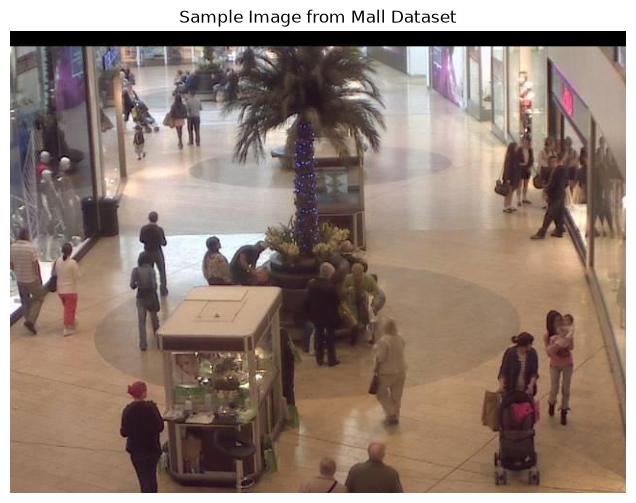

In [11]:
from PIL import Image
import matplotlib.pyplot as plt

if all_images:
    sample_path = all_images[0]
    img = Image.open(sample_path).convert("RGB")

    print("Lokasi gambar:", sample_path)
    print("Ukuran gambar:", img.size)

    plt.figure(figsize=(12, 6))
    plt.imshow(img)
    plt.title("Sample Image from Mall Dataset")
    plt.axis("off")
    plt.show()
else:
    print("Belum ada gambar yang ditemukan.")
    print("Periksa apakah folder frames berisi file gambar atau arsip ZIP.")


## 7. Validasi Lokasi Gambar

Tahap ini dilakukan untuk memastikan bahwa folder gambar
berada pada lokasi yang benar dan dapat diakses oleh Python.

Validasi lokasi diperlukan agar proses pembacaan dan analisis
gambar dapat dilakukan tanpa kesalahan path.


In [14]:
from pathlib import Path

print("Dataset path:", dataset_path)
print("Frames path:", frames_path)

if frames_path.exists():
    print("\nIsi folder frames:")
    for item in list(frames_path.iterdir())[:10]:
        print(item.name)
else:
    print("\nFolder frames tidak ditemukan.")

Dataset path: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset
Frames path: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset/frames

Isi folder frames:
.DS_Store
frames


In [15]:
project_path = Path(
    "/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting"
)

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

all_images = [
    p for p in project_path.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Jumlah gambar ditemukan:", len(all_images))

for path in all_images[:10]:
    print(path)

Jumlah gambar ditemukan: 2029
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/.venv/share/jupyter/kernels/python3/logo-64x64.png
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/.venv/share/jupyter/kernels/python3/logo-32x32.png
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/.venv/lib/python3.14/site-packages/ipykernel/resources/logo-64x64.png
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/.venv/lib/python3.14/site-packages/ipykernel/resources/logo-32x32.png
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/.venv/lib/python3.14/site-packages/scipy/ndimage/tests/dots.png
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/.venv/lib/python3.14/site-packages/matplotlib/mpl-data/images/matplotlib_large.png
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/.venv/lib/python3.14/site-packages/matplotlib/mpl-data/images/subplots_large.png
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/.venv/lib/python3.14/site-pa


## 8. Analisis Ground Truth

Ground truth merupakan data acuan yang digunakan untuk
mengevaluasi hasil penghitungan jumlah orang oleh model.

Pada dataset Mall, informasi ini disimpan dalam file MATLAB
dengan ekstensi `.mat`. Sebelum digunakan, struktur variabel
dan dimensinya perlu diperiksa untuk memahami format anotasi.

Pemeriksaan ini menjadi dasar untuk menentukan metode evaluasi
yang sesuai pada tahap selanjutnya.


In [16]:
from scipy.io import loadmat

gt_path = dataset_path / "mall_gt.mat"

gt_data = loadmat(gt_path)

print("Variabel dalam mall_gt.mat:")
for key, value in gt_data.items():
    if not key.startswith("__"):
        print(
            f"Nama variabel: {key}, "
            f"bentuk data: {value.shape}, "
            f"tipe data: {value.dtype}"
        )

Variabel dalam mall_gt.mat:
Nama variabel: frame, bentuk data: (1, 2000), tipe data: object
Nama variabel: count, bentuk data: (2000, 1), tipe data: uint8



## 9. Analisis Perspective dan Region of Interest

File `perspective_roi.mat` akan diperiksa untuk mengetahui
informasi perspektif kamera dan area pengamatan yang tersedia.

Informasi ini berpotensi membantu analisis crowd counting,
tetapi penggunaannya akan ditentukan berdasarkan struktur
dan isi data yang sebenarnya.


In [17]:
roi_path = dataset_path / "perspective_roi.mat"

roi_data = loadmat(roi_path)

print("Variabel dalam perspective_roi.mat:")
for key, value in roi_data.items():
    if not key.startswith("__"):
        print(
            f"Nama variabel: {key}, "
            f"bentuk data: {value.shape}, "
            f"tipe data: {value.dtype}"
        )

Variabel dalam perspective_roi.mat:
Nama variabel: roi, bentuk data: (1, 1), tipe data: [('mask', 'O')]
Nama variabel: pMapN, bentuk data: (480, 640), tipe data: float64



## 10. Visualisasi Perspective Map dan Region of Interest

Pada tahap ini, kita mengeksplorasi informasi perspektif dan
area pengamatan yang tersedia pada dataset.

Perspective map divisualisasikan untuk melihat variasi nilai
perspektif pada gambar, sedangkan ROI mask ditampilkan untuk
memahami area yang ditandai sebagai wilayah pengamatan.

Visualisasi ini membantu kita memahami karakteristik kamera
sebelum menentukan metode crowd counting.


Ukuran perspective map: (480, 640)
Nilai minimum: 0.7729269812318472
Nilai maksimum: 14.842639673521196
Jumlah nilai NaN: 0


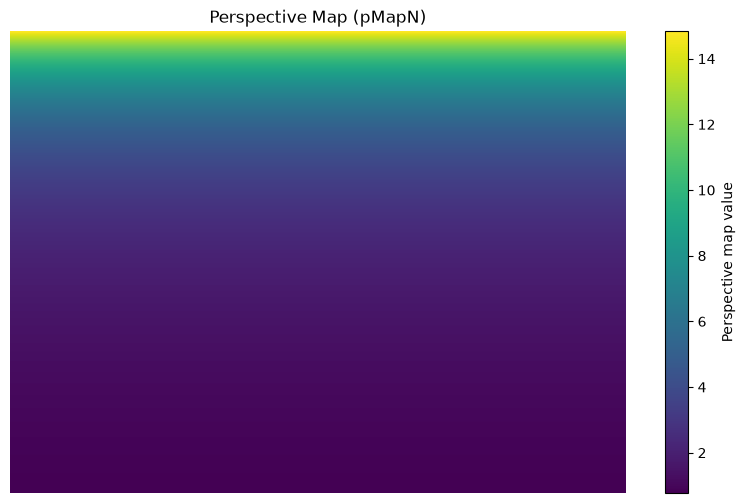

In [18]:
import matplotlib.pyplot as plt
import numpy as np

pmap = roi_data["pMapN"]

print("Ukuran perspective map:", pmap.shape)
print("Nilai minimum:", np.nanmin(pmap))
print("Nilai maksimum:", np.nanmax(pmap))
print("Jumlah nilai NaN:", np.isnan(pmap).sum())

plt.figure(figsize=(10, 6))
plt.imshow(pmap, cmap="viridis")
plt.colorbar(label="Perspective map value")
plt.title("Perspective Map (pMapN)")
plt.axis("off")
plt.show()

Ukuran ROI mask: (480, 640)
Tipe data: uint8
Nilai unik: [0 1]


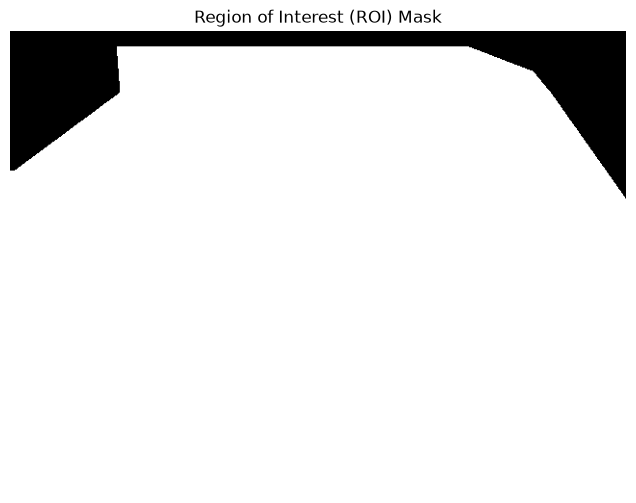

In [19]:
roi_struct = roi_data["roi"]
roi_mask = roi_struct["mask"][0, 0]

print("Ukuran ROI mask:", roi_mask.shape)
print("Tipe data:", roi_mask.dtype)
print("Nilai unik:", np.unique(roi_mask)[:10])

plt.figure(figsize=(10, 6))
plt.imshow(roi_mask, cmap="gray")
plt.title("Region of Interest (ROI) Mask")
plt.axis("off")
plt.show()


## 11. Analisis Ground Truth

Ground truth merupakan data acuan yang digunakan untuk
mengetahui jumlah orang sebenarnya pada setiap gambar.

Informasi ini diperlukan untuk membandingkan hasil prediksi
crowd counting dengan nilai aktual, sehingga performa metode
dapat dievaluasi secara objektif.

Pada tahap ini, struktur file `mall_gt.mat` diperiksa terlebih
dahulu sebelum menentukan cara membaca nilai anotasinya.


In [20]:
from scipy.io import loadmat
import numpy as np

gt_path = dataset_path / "mall_gt.mat"
gt_data = loadmat(gt_path)

print("Variabel ground truth:")

for key, value in gt_data.items():
    if not key.startswith("__"):
        print(
            f"{key}: shape={value.shape}, "
            f"dtype={value.dtype}"
        )

Variabel ground truth:
frame: shape=(1, 2000), dtype=object
count: shape=(2000, 1), dtype=uint8



### 11.1 Pemeriksaan Isi Anotasi

Setelah mengetahui nama variabel dan dimensinya, kita
memeriksa sebagian isi anotasi untuk memahami format data.

Pemeriksaan ini dilakukan agar jumlah orang aktual tidak
disimpulkan dari struktur yang belum terverifikasi.


In [21]:
for key, value in gt_data.items():
    if not key.startswith("__"):
        print(f"\nVariabel: {key}")
        print("Contoh isi:")
        print(value[:5] if value.ndim > 0 else value)


Variabel: frame
Contoh isi:
[[array([[(array([[126.77986348,  60.70477816],
                 [116.95051195,  47.59897611],
                 [175.10750853,  44.3225256 ],
                 [184.11774744,  45.14163823],
                 [192.30887372,  44.3225256 ],
                 [230.80716724,  42.68430034],
                 [190.67064846,  66.43856655],
                 [176.74573379,  70.53412969],
                 [134.97098976, 100.0221843 ],
                 [ 14.56143345, 215.51706485],
                 [ 57.1552901 , 229.44197952],
                 [148.07679181, 193.40102389],
                 [143.16211604, 236.81399317],
                 [210.32935154, 222.8890785 ],
                 [260.29522184, 221.25085324],
                 [348.75938567, 225.34641638],
                 [364.3225256 , 253.19624573],
                 [331.55802048, 249.10068259],
                 [136.60921502, 370.32935154],
                 [330.73890785, 453.87883959],
                 [387.25767918

In [22]:
from pathlib import Path

print("Lokasi dataset:", dataset_path)

for item in dataset_path.iterdir():
    print(
        "[FOLDER]" if item.is_dir() else "[FILE]",
        item.name
    )

print("\nJumlah file JPG di seluruh dataset:")

jpg_files = list(dataset_path.rglob("*.jpg"))
print(len(jpg_files))

for path in jpg_files[:5]:
    print(path)

Lokasi dataset: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset
[FILE] .DS_Store
[FILE] mall_crowd_counting.ipynb
[FOLDER] frames
[FILE] mall_gt.mat
[FILE] perspective_roi.mat

Jumlah file JPG di seluruh dataset:
2000
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset/frames/frames/seq_001642.jpg
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset/frames/frames/seq_001124.jpg
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset/frames/frames/seq_001130.jpg
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset/frames/frames/seq_001656.jpg
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/dataset/frames/frames/seq_000548.jpg



## 12. Visualisasi Sampel Dataset

Pada tahap ini, dilakukan visualisasi terhadap salah satu gambar
dari Mall Dataset untuk memahami kondisi visual data.

Visualisasi bertujuan mengamati kepadatan orang, sudut pandang
kamera, pencahayaan, dan kemungkinan adanya objek yang saling
menutupi. Karakteristik tersebut dapat memengaruhi performa
metode crowd counting.

Dataset ini berisi 2.000 gambar JPG yang digunakan sebagai
data input untuk analisis.


Jumlah gambar: 2000
Nama gambar: seq_000001.jpg
Ukuran gambar: (640, 480)


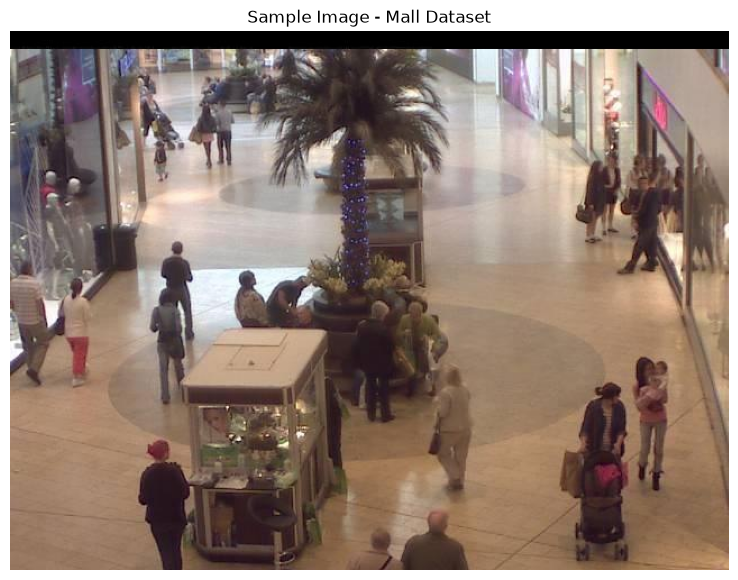

In [23]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Mencari semua gambar JPG
images = sorted(dataset_path.rglob("*.jpg"))

print("Jumlah gambar:", len(images))

# Ambil gambar pertama
sample_path = images[0]
sample_image = Image.open(sample_path).convert("RGB")

print("Nama gambar:", sample_path.name)
print("Ukuran gambar:", sample_image.size)

plt.figure(figsize=(12, 7))
plt.imshow(sample_image)
plt.title("Sample Image - Mall Dataset")
plt.axis("off")
plt.show()


## 13. Pemeriksaan Ground Truth

Ground truth merupakan informasi acuan untuk menilai hasil
penghitungan jumlah orang.

Pada tahap ini, file `mall_gt.mat` diperiksa untuk mengetahui
struktur variabel, dimensi array, dan format anotasinya.

Informasi tersebut diperlukan sebelum menentukan cara
memperoleh jumlah orang aktual pada setiap gambar.


In [24]:
from scipy.io import loadmat

gt_path = dataset_path / "mall_gt.mat"
gt_data = loadmat(gt_path)

for key, value in gt_data.items():
    if not key.startswith("__"):
        print(f"Variabel: {key}")
        print(f"Bentuk data: {value.shape}")
        print(f"Tipe data: {value.dtype}")
        print("-" * 40)

Variabel: frame
Bentuk data: (1, 2000)
Tipe data: object
----------------------------------------
Variabel: count
Bentuk data: (2000, 1)
Tipe data: uint8
----------------------------------------



## 14. Persiapan Model Computer Vision

Pada tahap ini, kita menyiapkan model untuk mendeteksi orang
pada gambar Mall Dataset.

Sebagai percobaan awal, kita menggunakan YOLO pretrained
untuk mendeteksi objek dengan kelas person. Hasilnya akan
menjadi baseline awal yang nantinya dapat dibandingkan dengan
ground truth dataset.

Perlu diperhatikan bahwa deteksi objek dan crowd counting
merupakan dua pendekatan yang berbeda. YOLO menghitung objek
yang berhasil dideteksi, sedangkan metode crowd counting
khusus dapat memperkirakan jumlah orang pada kondisi padat.


In [25]:
%pip install ultralytics

  Using cached pyyaml-6.0.3-cp314-cp314-macosx_11_0_arm64.whl.metadata (2.4 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached charset_normalizer-3.5.2-cp314-cp314-macosx_10_15_universal2.whl.metadata (46 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached markupsafe-3.0.4-cp314-cp314-macosx_11_0_arm64.whl.

In [26]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

print("Model YOLO berhasil dimuat.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/Users/nikentriwardani/Library/Application Support/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model YOLO berhasil dimuat.



## 15. Deteksi Orang pada Sampel Gambar

Model YOLO digunakan untuk mendeteksi objek kelas person
pada satu gambar CCTV.

Pada tahap ini, kita menghitung jumlah bounding box yang
diprediksi sebagai orang. Hasil tersebut merupakan jumlah
deteksi model, bukan jaminan jumlah orang sebenarnya.


Nama gambar: seq_000001.jpg
Jumlah orang terdeteksi: 20


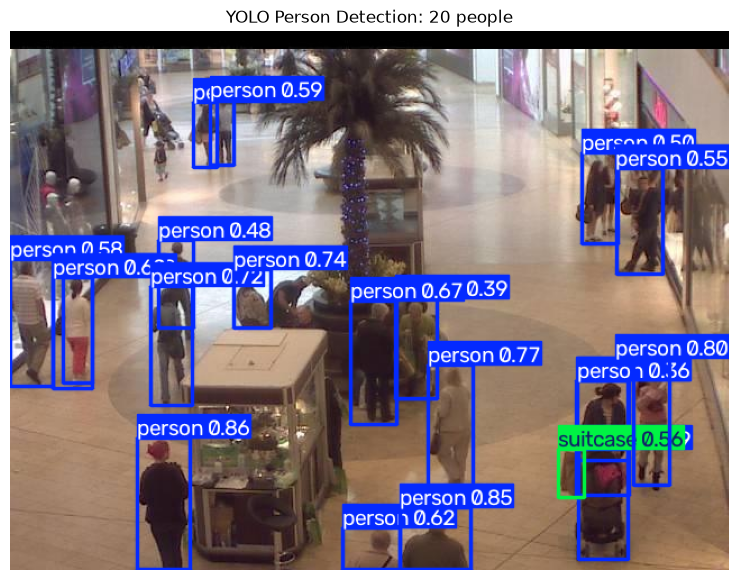

In [27]:
import matplotlib.pyplot as plt
import cv2

sample_path = str(images[0])

results = model.predict(
    source=sample_path,
    conf=0.25,
    verbose=False
)

person_count = sum(
    1
    for box in results[0].boxes
    if int(box.cls[0]) == 0
)

print("Nama gambar:", images[0].name)
print("Jumlah orang terdeteksi:", person_count)

annotated_image = results[0].plot()

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.title(f"YOLO Person Detection: {person_count} people")
plt.axis("off")
plt.show()


## 16. Evaluasi Hasil Deteksi

Evaluasi dilakukan untuk mengetahui seberapa dekat hasil
penghitungan model dengan jumlah orang yang tercatat pada
ground truth dataset.

Pada penelitian crowd counting, Mean Absolute Error (MAE)
dan Root Mean Squared Error (RMSE) dapat digunakan untuk
mengukur selisih antara jumlah prediksi dan jumlah aktual.

MAE mengukur rata-rata selisih absolut, sedangkan RMSE
memberikan penalti lebih besar pada kesalahan yang besar.

Sebelum menghitung kedua metrik tersebut, format ground truth
per gambar perlu dipastikan terlebih dahulu.


In [28]:
import numpy as np

for key, value in gt_data.items():
    if key.startswith("__"):
        continue

    print(f"\nVariabel: {key}")
    print("Shape:", value.shape)
    print("Dtype:", value.dtype)

    if value.dtype.names:
        print("Field:", value.dtype.names)
    else:
        print("Contoh data:")
        print(value.ravel()[:10])


Variabel: frame
Shape: (1, 2000)
Dtype: object
Contoh data:
[array([[(array([[     126.78,      60.705],
                [     116.95,      47.599],
                [     175.11,      44.323],
                [     184.12,      45.142],
                [     192.31,      44.323],
                [     230.81,      42.684],
                [     190.67,      66.439],
                [     176.75,      70.534],
                [     134.97,      100.02],
                [     14.561,      215.52],
                [     57.155,      229.44],
                [     148.08,       193.4],
                [     143.16,      236.81],
                [     210.33,      222.89],
                [      260.3,      221.25],
                [     348.76,      225.35],
                [     364.32,       253.2],
                [     331.56,       249.1],
                [     136.61,      370.33],
                [     330.74,      453.88],
                [     387.26,       433.4],
              

In [ ]:

### 16.1 Menentukan Jumlah Orang Aktual

Ground truth digunakan sebagai nilai pembanding untuk setiap
gambar. Jumlah orang aktual harus diperoleh sesuai dengan
struktur anotasi yang disediakan oleh dataset.

Nilai aktual dan prediksi harus merujuk pada gambar yang sama
agar evaluasi menghasilkan perbandingan yang valid.



## 17. Ekstraksi Ground Truth Count

File mall_gt.mat menyediakan anotasi untuk 2.000 frame.
Anotasi posisi kepala digunakan sebagai informasi lokasi orang,
sedangkan array jumlah orang digunakan sebagai acuan evaluasi.

Pada tahap ini, kita mengambil jumlah orang aktual untuk
setiap frame agar dapat dibandingkan dengan hasil prediksi
model Computer Vision.


In [29]:
for key, value in gt_data.items():
    if not key.startswith("__"):
        print(key, value.shape, value.dtype)

frame (1, 2000) object
count (2000, 1) uint8


In [30]:
ground_truth_counts = gt_data["count"].ravel()

print("Jumlah frame:", len(ground_truth_counts))
print("10 jumlah orang aktual pertama:", ground_truth_counts[:10])

Jumlah frame: 2000
10 jumlah orang aktual pertama: [29 30 35 31 26 26 28 27 29 31]



## 18. Evaluasi Prediksi YOLO

Prediksi YOLO dibandingkan dengan jumlah orang aktual pada
frame yang sama. Evaluasi menggunakan Mean Absolute Error
(MAE) dan Root Mean Squared Error (RMSE).

MAE menunjukkan rata-rata selisih absolut antara jumlah
prediksi dan jumlah aktual. RMSE memberikan penalti lebih
besar pada kesalahan hitung yang besar.



## 19. Identifikasi Variabel Ground Truth Count

File anotasi Mall Dataset memiliki struktur MATLAB yang perlu
diperiksa sebelum digunakan dalam evaluasi.

Pada tahap ini, kita mengidentifikasi variabel yang menyimpan
jumlah orang aktual pada setiap frame. Nilai tersebut akan
digunakan sebagai pembanding terhadap jumlah prediksi model.


In [31]:
for key, value in gt_data.items():
    if not key.startswith("__"):
        print(
            f"Nama: {key} | "
            f"Shape: {value.shape} | "
            f"Tipe: {value.dtype}"
        )

Nama: frame | Shape: (1, 2000) | Tipe: object
Nama: count | Shape: (2000, 1) | Tipe: uint8


In [33]:
import numpy as np

print("Daftar variabel dalam mall_gt.mat:")

for key, value in gt_data.items():
    if not key.startswith("__"):
        print(
            f"Nama variabel : {key}\n"
            f"Shape         : {value.shape}\n"
            f"Tipe data     : {value.dtype}\n"
            f"-----------------------------"
        )

Daftar variabel dalam mall_gt.mat:
Nama variabel : frame
Shape         : (1, 2000)
Tipe data     : object
-----------------------------
Nama variabel : count
Shape         : (2000, 1)
Tipe data     : uint8
-----------------------------


In [35]:
import numpy as np

# Mengambil jumlah orang aktual dari variabel count
ground_truth_counts = np.asarray(
    gt_data["count"]
).reshape(-1)

print("Jumlah frame:", len(ground_truth_counts))
print("10 jumlah orang pertama:", ground_truth_counts[:10])
print("Jumlah orang minimum:", ground_truth_counts.min())
print("Jumlah orang maksimum:", ground_truth_counts.max())
print("Rata-rata jumlah orang:", round(ground_truth_counts.mean(), 2))

Jumlah frame: 2000
10 jumlah orang pertama: [29 30 35 31 26 26 28 27 29 31]
Jumlah orang minimum: 13
Jumlah orang maksimum: 53
Rata-rata jumlah orang: 31.16


## 21. Memvalidasi Jumlah Gambar dan Ground Truth

Sebelum melakukan prediksi, jumlah gambar harus sesuai dengan jumlah anotasi ground truth. Pemeriksaan ini membantu memastikan bahwa setiap gambar memiliki nilai pembanding yang benar.

In [36]:
# Mengurutkan gambar berdasarkan nama file
images = sorted(dataset_path.rglob("*.jpg"))

print("Jumlah gambar:", len(images))
print("Jumlah ground truth:", len(ground_truth_counts))

assert len(images) == len(ground_truth_counts), (
    "Jumlah gambar tidak sama dengan jumlah ground truth!"
)

print("Validasi berhasil: jumlah gambar dan ground truth sesuai.")

Jumlah gambar: 2000
Jumlah ground truth: 2000
Validasi berhasil: jumlah gambar dan ground truth sesuai.


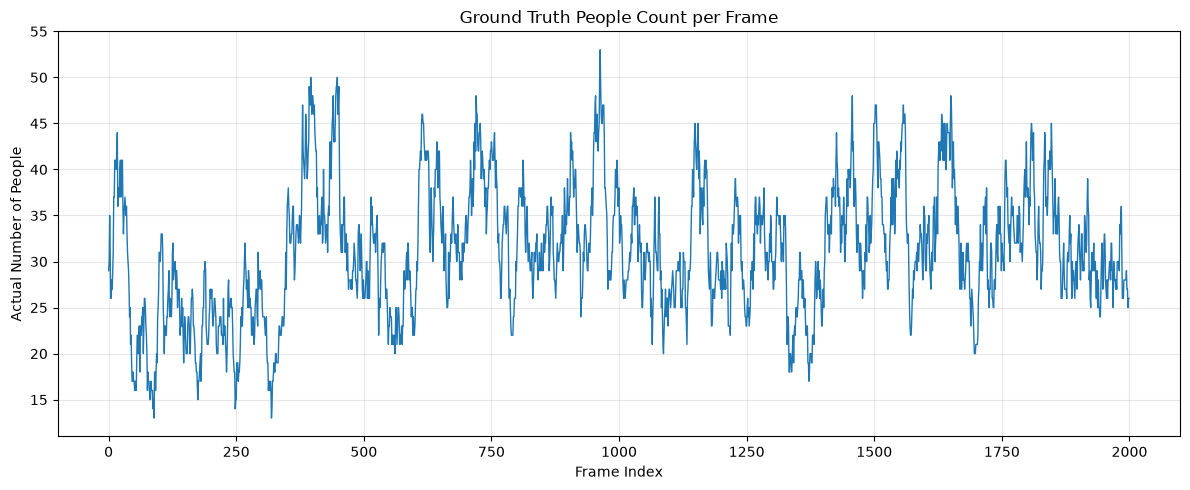

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(ground_truth_counts, linewidth=1)

plt.title("Ground Truth People Count per Frame")
plt.xlabel("Frame Index")
plt.ylabel("Actual Number of People")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 22. Memuat Model YOLO untuk Deteksi Orang

Pada tahap ini, kita menggunakan model YOLOv8n (*You Only Look Once, Nano*), yaitu model deteksi objek yang relatif ringan. Model ini digunakan untuk mendeteksi objek manusia pada gambar Mall Dataset.

Model pralatih akan menghasilkan bounding box untuk objek yang terdeteksi sebagai kelas `person`. Jumlah deteksi tersebut kemudian digunakan sebagai estimasi jumlah orang pada setiap gambar.

Perlu diperhatikan bahwa deteksi objek tidak selalu sama dengan crowd counting yang berbasis anotasi titik kepala. Pada gambar yang padat, sebagian orang mungkin tidak terdeteksi atau terdeteksi secara tidak tepat.

In [38]:
from ultralytics import YOLO

# Memuat model YOLOv8 Nano pralatih
model = YOLO("yolov8n.pt")

print("Model YOLO berhasil dimuat.")

Model YOLO berhasil dimuat.


## 23. Pengujian Deteksi Orang pada Satu Frame

Model YOLO diuji menggunakan satu gambar dari dataset. Hasil deteksi ditampilkan dalam bentuk bounding box yang mengelilingi objek yang dikenali sebagai manusia.

Parameter `conf=0.25` menentukan ambang kepercayaan minimum deteksi sebesar 25%. Nilai ini merupakan konfigurasi awal yang nantinya dapat disesuaikan.

Nama gambar: seq_000001.jpg
Ground truth: 29 orang
Prediksi YOLO: 20 orang


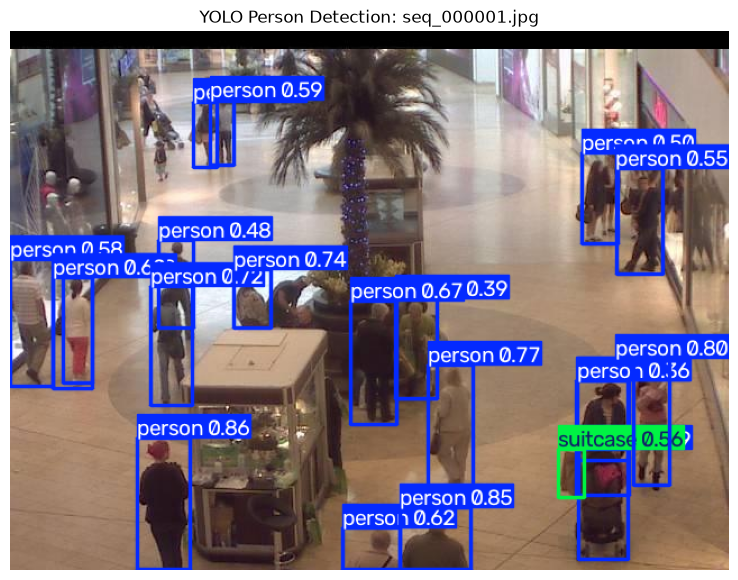

In [39]:
import matplotlib.pyplot as plt
import cv2
from IPython.display import display

# Memilih gambar pertama
sample_image = images[0]

# Melakukan deteksi
results = model.predict(
    source=str(sample_image),
    conf=0.25,
    verbose=False
)

# Menghitung deteksi kelas person (class ID 0 pada COCO)
result = results[0]
person_count = sum(
    1 for cls in result.boxes.cls.tolist()
    if int(cls) == 0
)

print("Nama gambar:", sample_image.name)
print("Ground truth:", int(ground_truth_counts[0]), "orang")
print("Prediksi YOLO:", person_count, "orang")

# Menampilkan gambar dengan bounding box
annotated_image = result.plot()
annotated_image = cv2.cvtColor(
    annotated_image, cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(annotated_image)
plt.title(f"YOLO Person Detection: {sample_image.name}")
plt.axis("off")
plt.show()

## 24. Evaluasi Awal pada 10 Frame

Pada tahap ini, model YOLO dijalankan pada 10 frame pertama. Jumlah orang hasil deteksi dibandingkan dengan jumlah aktual dalam variabel `count`.

Selisih antara prediksi dan ground truth digunakan untuk melihat kesalahan awal model. Evaluasi 10 frame ini masih bersifat uji coba, bukan hasil akhir performa model.

In [41]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 1.2 MB/s  0:00:09m0:00:0100:01

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [42]:
import pandas as pd

print("Pandas berhasil diimpor.")
print("Versi pandas:", pd.__version__)

Pandas berhasil diimpor.
Versi pandas: 3.1.0


In [43]:
sample_size = min(10, len(images))
records = []

## 25. Prediksi Jumlah Orang pada Seluruh Frame

Pada tahap ini, model YOLO digunakan untuk memprediksi jumlah orang pada seluruh frame Mall Dataset. Setiap hasil prediksi dipasangkan dengan ground truth yang sesuai berdasarkan urutan frame.

Hasil prediksi disimpan dalam sebuah DataFrame untuk memudahkan analisis kesalahan dan evaluasi performa model.

Karena proses ini melibatkan 2.000 gambar, waktu eksekusi bergantung pada spesifikasi komputer yang digunakan.

In [44]:
import pandas as pd
import numpy as np

predicted_counts = []

for i, image_path in enumerate(images):
    result = model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    # Menghitung deteksi yang termasuk kelas person
    person_count = sum(
        1 for cls in result.boxes.cls.tolist()
        if int(cls) == 0
    )

    predicted_counts.append(person_count)

    if (i + 1) % 100 == 0:
        print(f"Progress: {i + 1}/{len(images)} frame")

print("Prediksi selesai!")
print("Total prediksi:", len(predicted_counts))

Progress: 100/2000 frame
Progress: 200/2000 frame
Progress: 300/2000 frame
Progress: 400/2000 frame
Progress: 500/2000 frame
Progress: 600/2000 frame
Progress: 700/2000 frame
Progress: 800/2000 frame
Progress: 900/2000 frame
Progress: 1000/2000 frame
Progress: 1100/2000 frame
Progress: 1200/2000 frame
Progress: 1300/2000 frame
Progress: 1400/2000 frame
Progress: 1500/2000 frame
Progress: 1600/2000 frame
Progress: 1700/2000 frame
Progress: 1800/2000 frame
Progress: 1900/2000 frame
Progress: 2000/2000 frame
Prediksi selesai!
Total prediksi: 2000


## 26. Membandingkan Prediksi dan Ground Truth

Hasil prediksi YOLO dibandingkan dengan jumlah orang aktual pada setiap frame. Kolom absolute error menunjukkan besarnya kesalahan tanpa memperhatikan arah kesalahan.

Tabel ini menjadi dasar untuk menghitung metrik evaluasi model.

In [45]:
evaluation_df = pd.DataFrame({
    "Frame": [path.name for path in images],
    "Ground Truth": ground_truth_counts.astype(int),
    "YOLO Prediction": predicted_counts
})

evaluation_df["Error"] = (
    evaluation_df["YOLO Prediction"]
    - evaluation_df["Ground Truth"]
)

evaluation_df["Absolute Error"] = evaluation_df["Error"].abs()

display(evaluation_df.head(10))

,Frame,Ground Truth,YOLO Prediction,Error,Absolute Error
0,seq_000001.jpg,29,20,-9,9
1,seq_000002.jpg,30,22,-8,8
2,seq_000003.jpg,35,21,-14,14
3,seq_000004.jpg,31,17,-14,14
4,seq_000005.jpg,26,18,-8,8
5,seq_000006.jpg,26,18,-8,8
6,seq_000007.jpg,28,20,-8,8
7,seq_000008.jpg,27,21,-6,6
8,seq_000009.jpg,29,17,-12,12
9,seq_000010.jpg,31,22,-9,9


## 27. Evaluasi Performa Model Menggunakan MAE, RMSE, dan MAPE

Tiga metrik digunakan untuk mengevaluasi kesalahan prediksi jumlah orang.

- **MAE (Mean Absolute Error):** rata-rata selisih absolut antara prediksi dan jumlah aktual.
- **RMSE (Root Mean Squared Error):** memberikan penalti lebih besar pada kesalahan yang besar.
- **MAPE (Mean Absolute Percentage Error):** rata-rata kesalahan relatif terhadap nilai aktual. Metrik ini tidak terdefinisi ketika nilai aktual nol, sehingga frame dengan ground truth nol dikeluarkan dari perhitungan MAPE.

In [47]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = evaluation_df["Ground Truth"].to_numpy()
y_pred = evaluation_df["YOLO Prediction"].to_numpy()

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

# MAPE hanya dihitung untuk frame dengan ground truth > 0
nonzero_mask = y_true > 0

if nonzero_mask.any():
    mape = np.mean(
        np.abs(
            (y_true[nonzero_mask] - y_pred[nonzero_mask])
            / y_true[nonzero_mask]
        )
    ) * 100
else:
    mape = np.nan

print(f"MAE  : {mae:.2f} orang")
print(f"RMSE : {rmse:.2f} orang")
print(f"MAPE : {mape:.2f}%" if not np.isnan(mape) else "MAPE tidak dapat dihitung")

MAE  : 13.15 orang
RMSE : 13.82 orang
MAPE : 42.16%


## 28. Visualisasi Ground Truth dan Prediksi YOLO

Grafik ini membandingkan jumlah orang aktual dan hasil prediksi YOLO pada seluruh frame. Kedua garis membantu menunjukkan apakah prediksi mengikuti perubahan jumlah orang pada dataset.

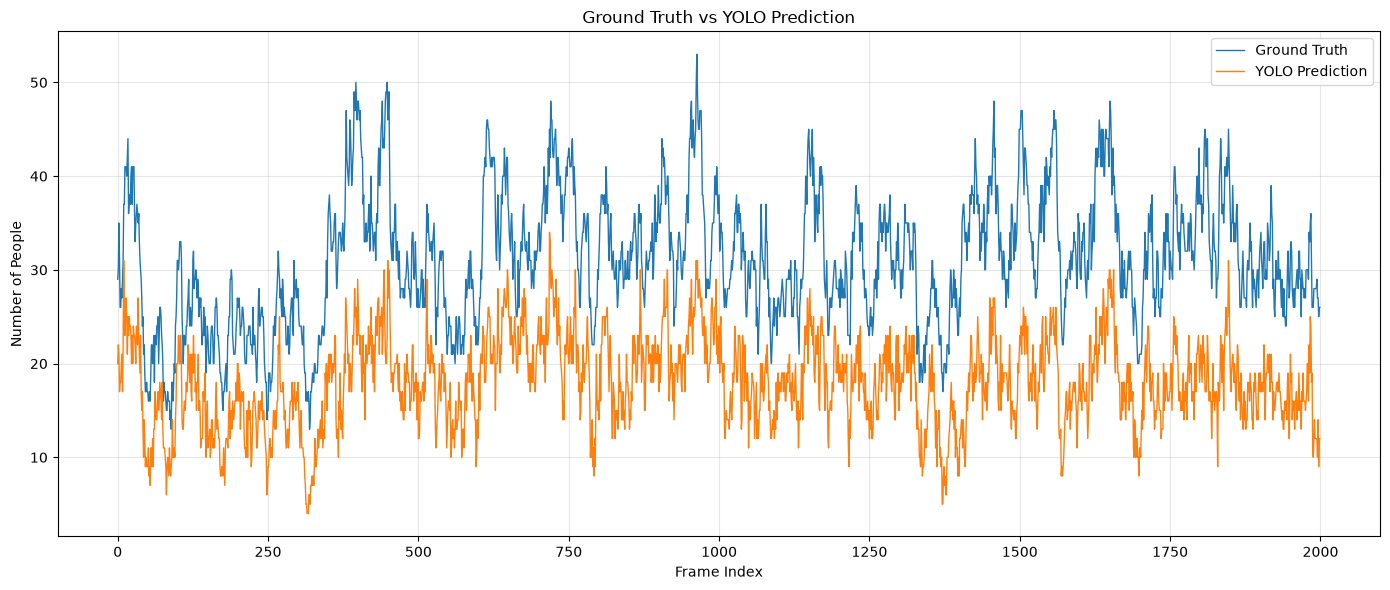

In [49]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_true,
    label="Ground Truth",
    linewidth=1
)

plt.plot(
    y_pred,
    label="YOLO Prediction",
    linewidth=1
)

plt.title("Ground Truth vs YOLO Prediction")
plt.xlabel("Frame Index")
plt.ylabel("Number of People")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 29. Analisis Kesalahan Prediksi

Analisis kesalahan digunakan untuk mengetahui apakah model YOLO cenderung menghitung orang terlalu sedikit (*underestimation*) atau terlalu banyak (*overestimation*).

Nilai error dihitung sebagai prediksi dikurangi ground truth. Error negatif menunjukkan jumlah prediksi lebih rendah daripada jumlah aktual, sedangkan error positif menunjukkan jumlah prediksi lebih tinggi.

In [50]:
# Ringkasan kesalahan prediksi
underestimation = (evaluation_df["Error"] < 0).sum()
overestimation = (evaluation_df["Error"] > 0).sum()
exact_predictions = (evaluation_df["Error"] == 0).sum()

print("Total frame:", len(evaluation_df))
print("Underestimation:", underestimation)
print("Overestimation:", overestimation)
print("Prediksi tepat:", exact_predictions)

print(
    "Persentase prediksi tepat:",
    round(exact_predictions / len(evaluation_df) * 100, 2),
    "%"
)

Total frame: 2000
Underestimation: 2000
Overestimation: 0
Prediksi tepat: 0
Persentase prediksi tepat: 0.0 %


## 30. Identifikasi Frame dengan Kesalahan Terbesar

Frame dengan absolute error tertinggi menunjukkan gambar yang paling sulit dihitung secara akurat oleh model. Frame ini dapat diperiksa kembali secara visual untuk melihat kemungkinan objek yang terhalang, ukuran manusia yang kecil, atau kepadatan kerumunan yang tinggi.

In [51]:
# Mengurutkan frame berdasarkan kesalahan terbesar
worst_frames = evaluation_df.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)

display(worst_frames)

,Frame,Ground Truth,YOLO Prediction,Error,Absolute Error
447,seq_000448.jpg,49,20,-29,29
446,seq_000447.jpg,49,20,-29,29
1808,seq_001809.jpg,45,17,-28,28
1809,seq_001810.jpg,44,17,-27,27
448,seq_000449.jpg,50,23,-27,27
440,seq_000441.jpg,48,21,-27,27
445,seq_000446.jpg,48,21,-27,27
1426,seq_001427.jpg,44,18,-26,26
386,seq_000387.jpg,46,20,-26,26
1503,seq_001504.jpg,47,21,-26,26


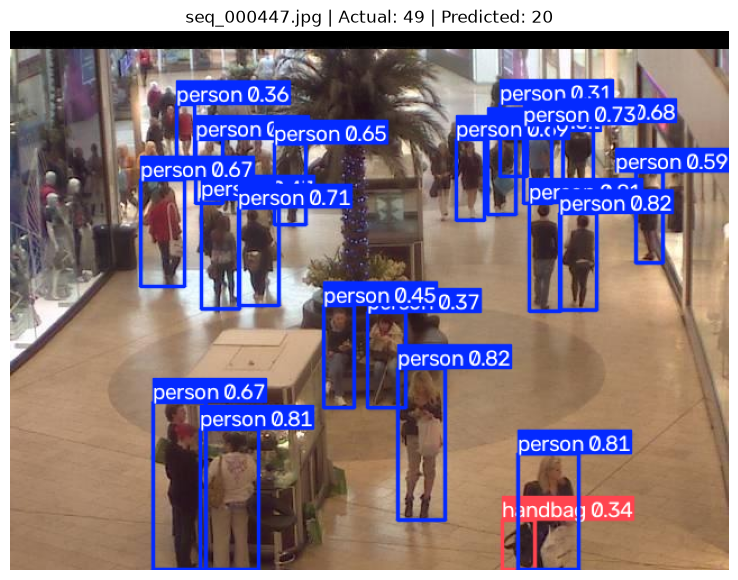

In [52]:
# Ambil frame dengan absolute error tertinggi
worst_index = evaluation_df["Absolute Error"].idxmax()
worst_image_path = images[worst_index]

result = model.predict(
    source=str(worst_image_path),
    conf=0.25,
    verbose=False
)[0]

annotated_image = cv2.cvtColor(
    result.plot(),
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(annotated_image)
plt.title(
    f"{worst_image_path.name} | "
    f"Actual: {y_true[worst_index]} | "
    f"Predicted: {y_pred[worst_index]}"
)
plt.axis("off")
plt.show()

## 31. Menyimpan Hasil Evaluasi

Hasil prediksi dan kesalahan setiap frame disimpan dalam format CSV. File ini dapat dibuka menggunakan Excel atau diimpor kembali ke Python untuk analisis lebih lanjut.

In [53]:
from pathlib import Path

output_path = dataset_path.parent / "yolo_evaluation_results.csv"

evaluation_df.to_csv(
    output_path,
    index=False
)

print("Hasil evaluasi tersimpan di:")
print(output_path)

Hasil evaluasi tersimpan di:
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/yolo_evaluation_results.csv


## 32. Analisis Performa Berdasarkan Tingkat Keramaian

Tahap ini mengelompokkan frame berdasarkan jumlah orang aktual (*ground truth*) menjadi tiga kategori: rendah, sedang, dan tinggi.

Kategori dibuat berdasarkan persentil ke-33 dan ke-67 dari distribusi ground truth agar pembagian mengikuti karakteristik dataset. Pendekatan ini digunakan untuk menganalisis hubungan antara tingkat keramaian dan kesalahan prediksi YOLO.

In [54]:
import numpy as np
import pandas as pd

# Menentukan batas kategori dari distribusi ground truth
q33 = evaluation_df["Ground Truth"].quantile(0.33)
q67 = evaluation_df["Ground Truth"].quantile(0.67)

def classify_crowd(count):
    if count <= q33:
        return "Rendah"
    elif count <= q67:
        return "Sedang"
    else:
        return "Tinggi"

evaluation_df["Crowd Level"] = (
    evaluation_df["Ground Truth"].apply(classify_crowd)
)

print(f"Batas persentil 33%: {q33:.2f}")
print(f"Batas persentil 67%: {q67:.2f}")

display(
    evaluation_df[
        ["Frame", "Ground Truth", "YOLO Prediction", "Absolute Error", "Crowd Level"]
    ].head(10)
)

Batas persentil 33%: 28.00
Batas persentil 67%: 34.00


,Frame,Ground Truth,YOLO Prediction,Absolute Error,Crowd Level
0,seq_000001.jpg,29,20,9,Sedang
1,seq_000002.jpg,30,22,8,Sedang
2,seq_000003.jpg,35,21,14,Tinggi
3,seq_000004.jpg,31,17,14,Sedang
4,seq_000005.jpg,26,18,8,Rendah
5,seq_000006.jpg,26,18,8,Rendah
6,seq_000007.jpg,28,20,8,Rendah
7,seq_000008.jpg,27,21,6,Rendah
8,seq_000009.jpg,29,17,12,Sedang
9,seq_000010.jpg,31,22,9,Sedang


## 33. Evaluasi Berdasarkan Tingkat Keramaian

MAE dihitung secara terpisah untuk kategori rendah, sedang, dan tinggi. Hasilnya menunjukkan kategori keramaian yang memiliki rata-rata kesalahan prediksi terbesar.

MAE yang lebih tinggi menunjukkan bahwa jumlah prediksi model rata-rata lebih jauh dari jumlah orang aktual pada kategori tersebut.

In [55]:
crowd_analysis = (
    evaluation_df.groupby("Crowd Level")
    .agg(
        Jumlah_Frame=("Frame", "count"),
        Rata_Rata_Aktual=("Ground Truth", "mean"),
        Rata_Rata_Prediksi=("YOLO Prediction", "mean"),
        MAE=("Absolute Error", "mean")
    )
    .reindex(["Rendah", "Sedang", "Tinggi"])
    .round(2)
)

display(crowd_analysis)

,Jumlah_Frame,Rata_Rata_Aktual,Rata_Rata_Prediksi,MAE
Crowd Level,,,,
Rendah,716,24.04,14.03,10.01
Sedang,688,31.35,18.36,12.99
Tinggi,596,39.48,22.37,17.11


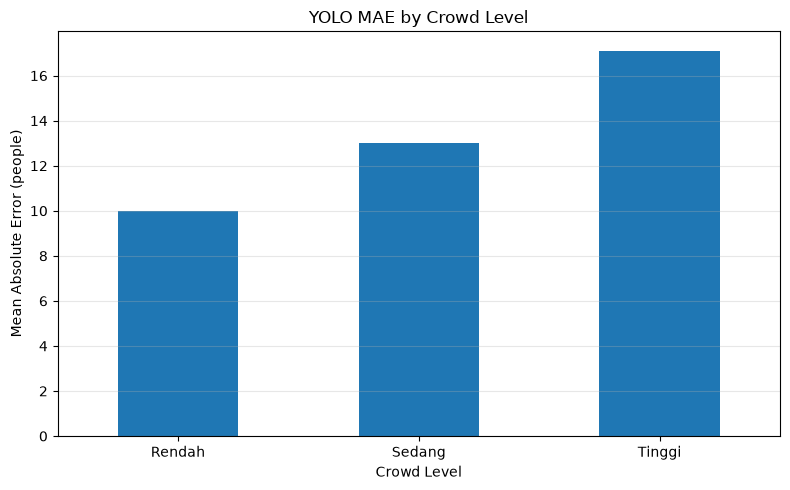

In [56]:
plt.figure(figsize=(8, 5))

crowd_analysis["MAE"].plot(kind="bar")

plt.title("YOLO MAE by Crowd Level")
plt.xlabel("Crowd Level")
plt.ylabel("Mean Absolute Error (people)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
output_summary = dataset_path.parent / "yolo_crowd_level_analysis.csv"

crowd_analysis.to_csv(output_summary)

print("Ringkasan analisis tersimpan di:")
print(output_summary)

Ringkasan analisis tersimpan di:
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/yolo_crowd_level_analysis.csv


## 34. Eksperimen Confidence Threshold YOLO

Confidence threshold adalah nilai minimum keyakinan model untuk menerima suatu deteksi. Deteksi dengan confidence di bawah threshold akan diabaikan.

Eksperimen ini membandingkan threshold 0.10, 0.25, dan 0.50 pada sampel frame yang sama. Tujuannya adalah mengetahui bagaimana perubahan threshold memengaruhi jumlah orang yang terdeteksi dan kesalahan prediksi.

Eksperimen ini merupakan analisis sensitivitas parameter, bukan proses pelatihan ulang model.

In [58]:
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

# Threshold yang akan dibandingkan
confidence_thresholds = [0.10, 0.25, 0.50]

# Gunakan 200 frame pertama
experiment_size = min(200, len(images))

threshold_results = []

for conf_threshold in confidence_thresholds:
    predictions = []

    for i in range(experiment_size):
        result = model.predict(
            source=str(images[i]),
            conf=conf_threshold,
            verbose=False
        )[0]

        person_count = sum(
            1 for cls in result.boxes.cls.tolist()
            if int(cls) == 0
        )

        predictions.append(person_count)

    actual = ground_truth_counts[:experiment_size].astype(int)

    mae = mean_absolute_error(actual, predictions)

    threshold_results.append({
        "Confidence Threshold": conf_threshold,
        "MAE": round(mae, 3),
        "Rata-rata Ground Truth": round(float(actual.mean()), 2),
        "Rata-rata Prediksi": round(float(np.mean(predictions)), 2)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

,Confidence Threshold,MAE,Rata-rata Ground Truth,Rata-rata Prediksi
0,0.10,3.770,25.12,21.86
1,0.25,9.565,25.12,15.56
2,0.50,13.660,25.12,11.46


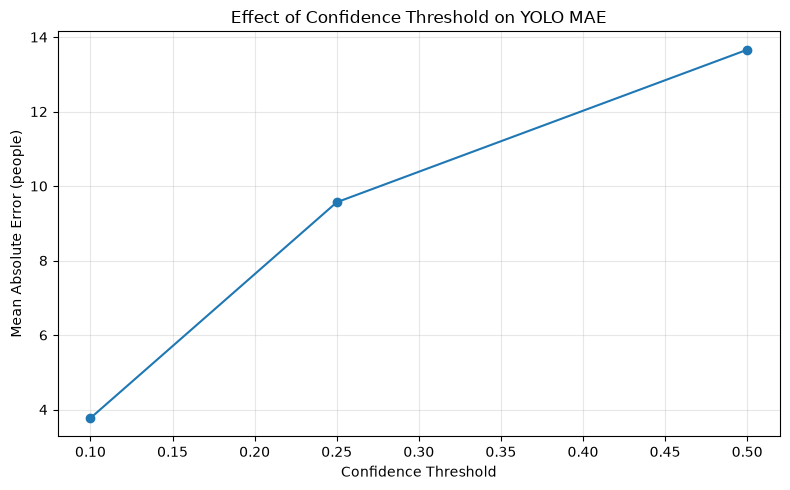

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Confidence Threshold"],
    threshold_df["MAE"],
    marker="o"
)

plt.title("Effect of Confidence Threshold on YOLO MAE")
plt.xlabel("Confidence Threshold")
plt.ylabel("Mean Absolute Error (people)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
output_threshold = (
    dataset_path.parent / "yolo_threshold_experiment.csv"
)

threshold_df.to_csv(output_threshold, index=False)

print("Hasil eksperimen tersimpan di:")
print(output_threshold)

Hasil eksperimen tersimpan di:
/Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/yolo_threshold_experiment.csv


## 35. Analisis Hubungan Ground Truth dan Prediction Error

Tahap ini menganalisis hubungan antara jumlah orang aktual dan kesalahan prediksi model YOLO.

Signed error didefinisikan sebagai jumlah prediksi dikurangi jumlah aktual. Nilai negatif menunjukkan underestimation, sedangkan nilai positif menunjukkan overestimation.

Analisis ini bersifat eksploratif. Hubungan antara jumlah orang dan error tidak dengan sendirinya membuktikan penyebab kesalahan model.

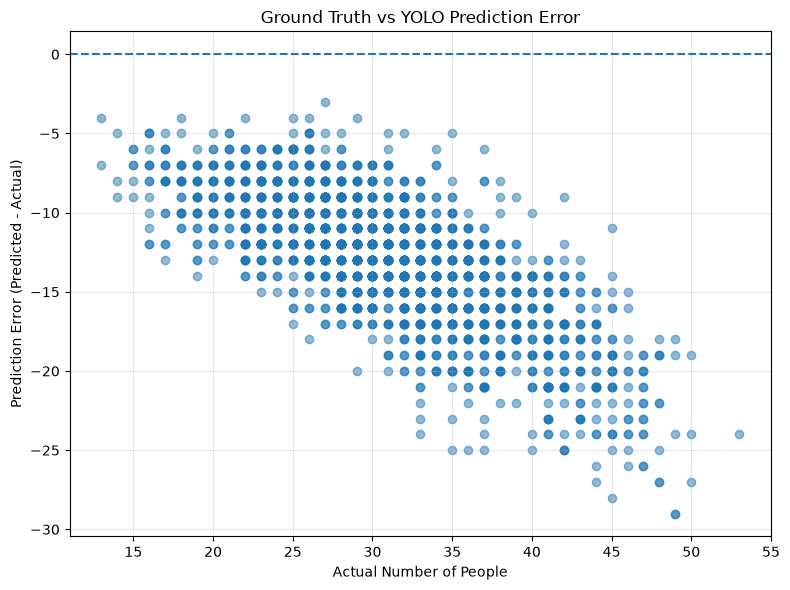

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    evaluation_df["Ground Truth"],
    evaluation_df["Error"],
    alpha=0.5
)

plt.axhline(0, linestyle="--")

plt.title("Ground Truth vs YOLO Prediction Error")
plt.xlabel("Actual Number of People")
plt.ylabel("Prediction Error (Predicted - Actual)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 36. Analisis Bias Prediksi

Bias prediksi dihitung menggunakan rata-rata signed error. Nilai negatif menunjukkan kecenderungan model menghasilkan jumlah prediksi lebih rendah daripada ground truth, sedangkan nilai positif menunjukkan kecenderungan sebaliknya.

In [62]:
mean_error = evaluation_df["Error"].mean()

print(f"Mean Error (bias): {mean_error:.2f} orang")

if mean_error < 0:
    print("Interpretasi: model cenderung underestimation.")
elif mean_error > 0:
    print("Interpretasi: model cenderung overestimation.")
else:
    print("Interpretasi: rata-rata signed error sama dengan nol.")

Mean Error (bias): -13.15 orang
Interpretasi: model cenderung underestimation.


In [63]:
import numpy as np
import pandas as pd

y_true = evaluation_df["Ground Truth"].to_numpy()
y_pred = evaluation_df["YOLO Prediction"].to_numpy()

mae_value = np.mean(np.abs(y_pred - y_true))
rmse_value = np.sqrt(np.mean((y_pred - y_true) ** 2))
mean_error_value = np.mean(y_pred - y_true)

nonzero_mask = y_true > 0

mape_value = (
    np.mean(
        np.abs(
            (y_pred[nonzero_mask] - y_true[nonzero_mask])
            / y_true[nonzero_mask]
        )
    ) * 100
    if nonzero_mask.any()
    else np.nan
)

metrics_df = pd.DataFrame([{
    "Model": "YOLOv8n pretrained",
    "Number of Frames": len(y_true),
    "MAE": mae_value,
    "RMSE": rmse_value,
    "MAPE (%)": mape_value,
    "Mean Error": mean_error_value
}])

display(metrics_df.round(3))

metrics_path = dataset_path.parent / "yolo_summary_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

print("Ringkasan metrik tersimpan di:", metrics_path)

,Model,Number of Frames,MAE,RMSE,MAPE (%),Mean Error
0,YOLOv8n pretrained,2000,13.15,13.818,42.159,-13.15


Ringkasan metrik tersimpan di: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/yolo_summary_metrics.csv


## 37. Distribusi Kesalahan Prediksi YOLO

Histogram digunakan untuk melihat sebaran kesalahan absolut model pada seluruh frame. Visualisasi ini membantu mengetahui apakah kesalahan model umumnya kecil atau terdapat banyak frame dengan kesalahan besar.

Kesalahan absolut dihitung dari nilai mutlak selisih antara prediksi YOLO dan ground truth.

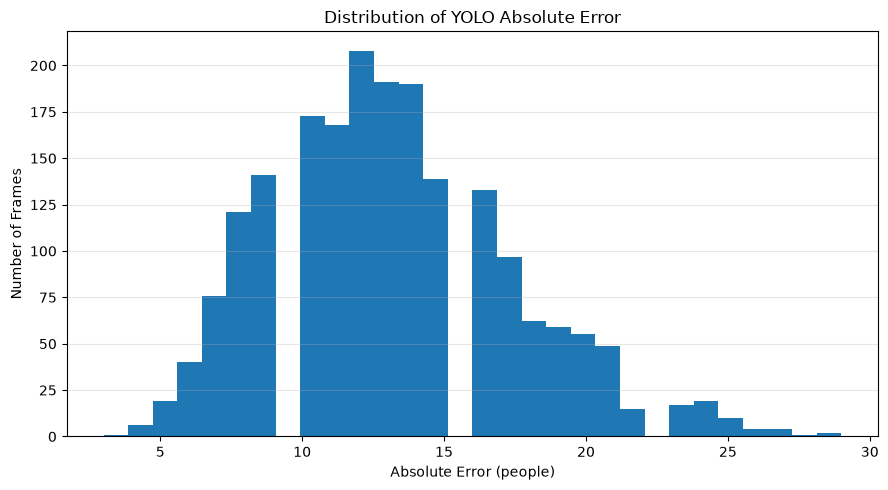

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    evaluation_df["Absolute Error"],
    bins=30
)

plt.title("Distribution of YOLO Absolute Error")
plt.xlabel("Absolute Error (people)")
plt.ylabel("Number of Frames")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 38. Actual Count vs Predicted Count

Scatter plot membandingkan jumlah orang aktual dengan jumlah yang diprediksi model. Garis diagonal menunjukkan kondisi prediksi ideal, yaitu ketika jumlah prediksi sama dengan jumlah aktual.

Semakin dekat titik-titik terhadap garis diagonal, semakin dekat prediksi dengan ground truth.

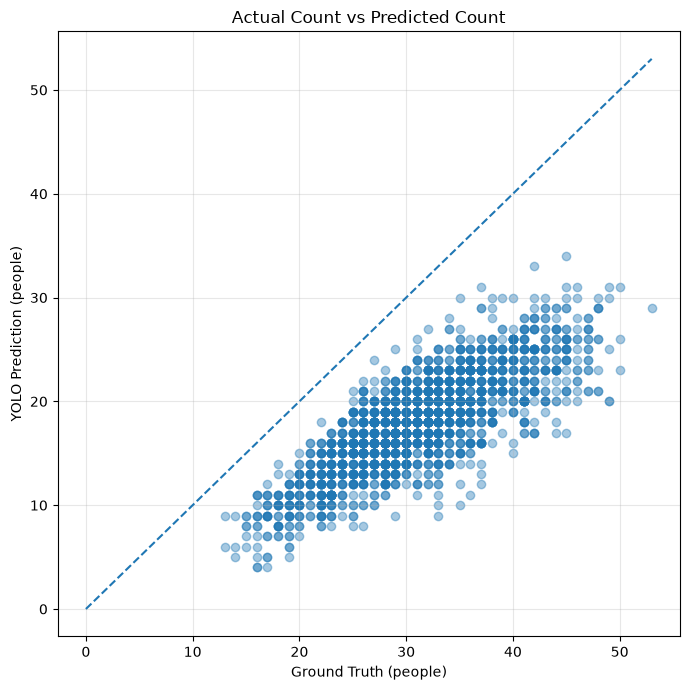

In [65]:
y_true = evaluation_df["Ground Truth"].to_numpy()
y_pred = evaluation_df["YOLO Prediction"].to_numpy()

plt.figure(figsize=(7, 7))

plt.scatter(y_true, y_pred, alpha=0.4)

max_value = max(y_true.max(), y_pred.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.title("Actual Count vs Predicted Count")
plt.xlabel("Ground Truth (people)")
plt.ylabel("YOLO Prediction (people)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [66]:
import numpy as np
import pandas as pd
from pathlib import Path

y_true = evaluation_df["Ground Truth"].to_numpy()
y_pred = evaluation_df["YOLO Prediction"].to_numpy()

report = {
    "Model": "YOLOv8n pretrained",
    "Number of Frames": len(evaluation_df),
    "Mean Ground Truth": y_true.mean(),
    "Mean Prediction": y_pred.mean(),
    "MAE": np.mean(np.abs(y_pred - y_true)),
    "RMSE": np.sqrt(np.mean((y_pred - y_true) ** 2)),
    "Mean Error": np.mean(y_pred - y_true)
}

nonzero_mask = y_true > 0

report["MAPE (%)"] = (
    np.mean(
        np.abs(
            (y_pred[nonzero_mask] - y_true[nonzero_mask])
            / y_true[nonzero_mask]
        )
    ) * 100
    if nonzero_mask.any()
    else np.nan
)

report_df = pd.DataFrame([report]).round(3)

display(report_df)

report_path = (
    dataset_path.parent / "mall_crowd_counting_report.csv"
)

report_df.to_csv(report_path, index=False)

print("Laporan tersimpan di:", report_path)

,Model,Number of Frames,Mean Ground Truth,Mean Prediction,MAE,RMSE,Mean Error,MAPE (%)
0,YOLOv8n pretrained,2000,31.158,18.007,13.15,13.818,-13.15,42.159


Laporan tersimpan di: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/mall_crowd_counting_report.csv


## 39. Eksplorasi Anotasi Titik Kepala

Variabel `frame` pada file `mall_gt.mat` menyimpan anotasi lokasi kepala untuk setiap frame. Anotasi ini dapat digunakan sebagai informasi spasial dalam pengembangan model crowd counting.

Pada tahap ini, kita memeriksa struktur anotasi dan memvisualisasikan titik kepala pada satu gambar sampel untuk memastikan koordinatnya sesuai dengan gambar.

In [67]:
import numpy as np

# Mengambil anotasi untuk frame pertama
frame_annotations = gt_data["frame"]

print("Shape anotasi:", frame_annotations.shape)
print("Tipe data:", frame_annotations.dtype)
print("Tipe elemen pertama:", type(frame_annotations[0, 0]))
print("Isi anotasi pertama:")
print(frame_annotations[0, 0])

Shape anotasi: (1, 2000)
Tipe data: object
Tipe elemen pertama: <class 'numpy.ndarray'>
Isi anotasi pertama:
[[(array([[     126.78,      60.705],
         [     116.95,      47.599],
         [     175.11,      44.323],
         [     184.12,      45.142],
         [     192.31,      44.323],
         [     230.81,      42.684],
         [     190.67,      66.439],
         [     176.75,      70.534],
         [     134.97,      100.02],
         [     14.561,      215.52],
         [     57.155,      229.44],
         [     148.08,       193.4],
         [     143.16,      236.81],
         [     210.33,      222.89],
         [      260.3,      221.25],
         [     348.76,      225.35],
         [     364.32,       253.2],
         [     331.56,       249.1],
         [     136.61,      370.33],
         [     330.74,      453.88],
         [     387.26,       433.4],
         [     397.09,      315.45],
         [     531.42,      324.46],
         [     563.37,      299.89],
  

In [68]:
first_annotation = frame_annotations[0, 0]

print("Shape:", getattr(first_annotation, "shape", None))
print("Dtype:", getattr(first_annotation, "dtype", None))
print("Nama field:", getattr(
    getattr(first_annotation, "dtype", None),
    "names",
    None
))

Shape: (1, 1)
Dtype: [('loc', 'O')]
Nama field: ('loc',)


## 40. Pemeriksaan Struktur Anotasi Titik Kepala

Anotasi titik kepala pada Mall Dataset akan digunakan untuk memvisualisasikan posisi orang dan mempersiapkan data bagi model crowd counting.

Sebelum ekstraksi koordinat dilakukan, struktur data diperiksa untuk mengetahui apakah anotasi disimpan sebagai array numerik atau struktur MATLAB bersarang.

In [69]:
# Periksa anotasi frame pertama
annotation = gt_data["frame"][0, 0]

print("Tipe objek:", type(annotation))
print("Shape:", getattr(annotation, "shape", None))
print("Dtype:", getattr(annotation, "dtype", None))

if isinstance(annotation, np.ndarray):
    print("Jumlah dimensi:", annotation.ndim)

    if annotation.dtype.names:
        print("Nama field:", annotation.dtype.names)

    print("Contoh isi anotasi:")
    print(annotation[:3] if annotation.ndim > 0 else annotation)
else:
    print("Isi anotasi:")
    print(annotation)

Tipe objek: <class 'numpy.ndarray'>
Shape: (1, 1)
Dtype: [('loc', 'O')]
Jumlah dimensi: 2
Nama field: ('loc',)
Contoh isi anotasi:
[[(array([[     126.78,      60.705],
         [     116.95,      47.599],
         [     175.11,      44.323],
         [     184.12,      45.142],
         [     192.31,      44.323],
         [     230.81,      42.684],
         [     190.67,      66.439],
         [     176.75,      70.534],
         [     134.97,      100.02],
         [     14.561,      215.52],
         [     57.155,      229.44],
         [     148.08,       193.4],
         [     143.16,      236.81],
         [     210.33,      222.89],
         [      260.3,      221.25],
         [     348.76,      225.35],
         [     364.32,       253.2],
         [     331.56,       249.1],
         [     136.61,      370.33],
         [     330.74,      453.88],
         [     387.26,       433.4],
         [     397.09,      315.45],
         [     531.42,      324.46],
         [     56

In [70]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

annotation = np.asarray(gt_data["frame"][0, 0])

# Ubah menjadi koordinat N x 2 jika formatnya memang berupa pasangan x, y
if (
    annotation.ndim == 2
    and annotation.shape[1] == 2
    and np.issubdtype(annotation.dtype, np.number)
):
    points = annotation

    image = Image.open(images[0]).convert("RGB")

    plt.figure(figsize=(12, 7))
    plt.imshow(image)
    plt.scatter(
        points[:, 0],
        points[:, 1],
        s=12,
        marker="x"
    )
    plt.title(
        f"Head Annotations — {images[0].name} "
        f"({len(points)} points)"
    )
    plt.axis("on")
    plt.show()

    print("Jumlah titik anotasi:", len(points))
    print("Ground truth count:", int(ground_truth_counts[0]))
else:
    print("Format anotasi bukan array N x 2.")
    print("Shape yang ditemukan:", annotation.shape)
    print("Perlu penyesuaian ekstraksi berdasarkan struktur anotasi.")

Format anotasi bukan array N x 2.
Shape yang ditemukan: (1, 1)
Perlu penyesuaian ekstraksi berdasarkan struktur anotasi.


## 41. Ekstraksi Anotasi Titik Kepala

Tahap ini menyiapkan anotasi lokasi kepala dari variabel `frame` pada Mall Dataset. Setiap frame memiliki sejumlah titik anotasi yang merepresentasikan posisi kepala orang.

Jumlah titik anotasi akan dibandingkan dengan variabel `count` untuk memastikan konsistensi ground truth sebelum data digunakan dalam proses pelatihan model.

In [71]:
import numpy as np

frame_annotations = gt_data["frame"]

for i in range(3):
    annotation = frame_annotations[0, i]

    print(f"\nFrame {i + 1}")
    print("Tipe:", type(annotation))
    print("Shape:", getattr(annotation, "shape", None))
    print("Dtype:", getattr(annotation, "dtype", None))
    print("Jumlah ground truth:", int(ground_truth_counts[i]))

    if isinstance(annotation, np.ndarray):
        print("Contoh isi:", annotation.reshape(-1)[:10])


Frame 1
Tipe: <class 'numpy.ndarray'>
Shape: (1, 1)
Dtype: [('loc', 'O')]
Jumlah ground truth: 29
Contoh isi: [(array([[     126.78,      60.705],
        [     116.95,      47.599],
        [     175.11,      44.323],
        [     184.12,      45.142],
        [     192.31,      44.323],
        [     230.81,      42.684],
        [     190.67,      66.439],
        [     176.75,      70.534],
        [     134.97,      100.02],
        [     14.561,      215.52],
        [     57.155,      229.44],
        [     148.08,       193.4],
        [     143.16,      236.81],
        [     210.33,      222.89],
        [      260.3,      221.25],
        [     348.76,      225.35],
        [     364.32,       253.2],
        [     331.56,       249.1],
        [     136.61,      370.33],
        [     330.74,      453.88],
        [     387.26,       433.4],
        [     397.09,      315.45],
        [     531.42,      324.46],
        [     563.37,      299.89],
        [     581.39,   

In [72]:
def extract_points(annotation):
    """Mengembalikan koordinat jika anotasi berbentuk N x 2."""
    arr = np.asarray(annotation)

    if (
        arr.ndim == 2
        and arr.shape[1] == 2
        and np.issubdtype(arr.dtype, np.number)
    ):
        return arr

    return None


annotation_counts = []

for i in range(len(ground_truth_counts)):
    points = extract_points(frame_annotations[0, i])

    annotation_counts.append(
        len(points) if points is not None else None
    )

print("Contoh jumlah titik:", annotation_counts[:10])
print("Contoh ground truth:", ground_truth_counts[:10])

valid_frames = [
    i for i, count in enumerate(annotation_counts)
    if count is not None
]

print("Frame dengan format koordinat N x 2:", len(valid_frames))

Contoh jumlah titik: [None, None, None, None, None, None, None, None, None, None]
Contoh ground truth: [29 30 35 31 26 26 28 27 29 31]
Frame dengan format koordinat N x 2: 0


## 42. Pemeriksaan Struktur Internal Anotasi

Anotasi pada file `mall_gt.mat` disimpan dalam struktur yang belum sesuai dengan format koordinat numerik dua kolom. Tahap ini memeriksa struktur internal anotasi untuk menemukan field yang menyimpan lokasi kepala.

Hasil pemeriksaan akan digunakan untuk menentukan metode ekstraksi koordinat yang tepat.

In [73]:
# Periksa satu anotasi secara lebih mendalam
annotation = gt_data["frame"][0, 0]

print("Tipe:", type(annotation))
print("Shape:", getattr(annotation, "shape", None))
print("Dtype:", getattr(annotation, "dtype", None))
print("Nama field:", getattr(
    getattr(annotation, "dtype", None),
    "names",
    None
))

print("\nRepresentasi lengkap anotasi pertama:")
print(repr(annotation))

Tipe: <class 'numpy.ndarray'>
Shape: (1, 1)
Dtype: [('loc', 'O')]
Nama field: ('loc',)

Representasi lengkap anotasi pertama:
array([[(array([[     126.78,      60.705],
               [     116.95,      47.599],
               [     175.11,      44.323],
               [     184.12,      45.142],
               [     192.31,      44.323],
               [     230.81,      42.684],
               [     190.67,      66.439],
               [     176.75,      70.534],
               [     134.97,      100.02],
               [     14.561,      215.52],
               [     57.155,      229.44],
               [     148.08,       193.4],
               [     143.16,      236.81],
               [     210.33,      222.89],
               [      260.3,      221.25],
               [     348.76,      225.35],
               [     364.32,       253.2],
               [     331.56,       249.1],
               [     136.61,      370.33],
               [     330.74,      453.88],
             

In [74]:
import numpy as np

annotation = gt_data["frame"][0, 0]
field_names = getattr(annotation.dtype, "names", None)

if field_names:
    for field in field_names:
        value = annotation[field]
        print(f"\nField: {field}")
        print("Shape:", getattr(value, "shape", None))
        print("Dtype:", getattr(value, "dtype", None))
        print("Contoh isi:", repr(value)[:1000])
else:
    print("Tidak ditemukan nama field pada struktur ini.")
    print("Tipe objek:", type(annotation))
    print("Isi:", repr(annotation)[:2000])


Field: loc
Shape: (1, 1)
Dtype: object
Contoh isi: array([[array([[     126.78,      60.705],
               [     116.95,      47.599],
               [     175.11,      44.323],
               [     184.12,      45.142],
               [     192.31,      44.323],
               [     230.81,      42.684],
               [     190.67,      66.439],
               [     176.75,      70.534],
               [     134.97,      100.02],
               [     14.561,      215.52],
               [     57.155,      229.44],
               [     148.08,       193.4],
               [     143.16,      236.81],
               [     210.33,      222.89],
               [      260.3,      221.25],
               [     348.76,      225.35],
               [     364.32,       253.2],
               [     331.56,       249.1],
               [     136.61,      370.33],
               [     330.74,      453.88],
               [     387.26,       433.4],
               [     397.09,      315.45],
  

## 43. Ekstraksi Koordinat Titik Kepala

Anotasi lokasi kepala pada Mall Dataset disimpan dalam field `loc` pada setiap elemen variabel `frame`. Data tersebut berisi pasangan koordinat \(x,y\) untuk setiap kepala yang dianotasi.

Tahap ini mengekstrak koordinat dari field `loc` untuk seluruh frame, kemudian memeriksa kesesuaiannya dengan variabel ground truth `count`.

In [75]:
import numpy as np

frame_annotations = gt_data["frame"]

def extract_head_points(frame_item):
    # Mengambil field loc dari struktur MATLAB
    loc = frame_item["loc"]

    # Mengurai array object bersarang
    while isinstance(loc, np.ndarray) and loc.dtype == object:
        if loc.size == 1:
            loc = loc.item()
        else:
            break

    points = np.asarray(loc, dtype=float)

    # Memastikan koordinat berbentuk N x 2
    if points.size == 0:
        return np.empty((0, 2), dtype=float)

    if points.ndim == 1 and points.size == 2:
        points = points.reshape(1, 2)

    if points.ndim != 2 or points.shape[1] != 2:
        raise ValueError(
            f"Format koordinat tidak sesuai: {points.shape}"
        )

    return points


# Ekstraksi untuk frame pertama
points_first = extract_head_points(frame_annotations[0, 0])

print("Shape koordinat:", points_first.shape)
print("Jumlah titik kepala:", len(points_first))
print("Ground truth count:", int(ground_truth_counts[0]))
print("Lima koordinat pertama:\n", points_first[:5])

Shape koordinat: (29, 2)
Jumlah titik kepala: 29
Ground truth count: 29
Lima koordinat pertama:
 [[     126.78      60.705]
 [     116.95      47.599]
 [     175.11      44.323]
 [     184.12      45.142]
 [     192.31      44.323]]


In [76]:
head_points = [
    extract_head_points(frame_annotations[0, i])
    for i in range(len(ground_truth_counts))
]

annotation_counts = np.array([
    len(points) for points in head_points
])

matches = annotation_counts == ground_truth_counts

print("Total frame:", len(head_points))
print("Frame dengan jumlah titik sesuai:", int(matches.sum()))
print("Frame dengan jumlah titik berbeda:", int((~matches).sum()))

if matches.all():
    print("Validasi berhasil: semua jumlah titik sesuai ground truth.")
else:
    mismatch_indices = np.where(~matches)[0][:10]
    print("\nContoh frame yang tidak sesuai:")
    for i in mismatch_indices:
        print(
            f"Frame {i + 1}: "
            f"anotasi={annotation_counts[i]}, "
            f"ground truth={ground_truth_counts[i]}"
        )

Total frame: 2000
Frame dengan jumlah titik sesuai: 2000
Frame dengan jumlah titik berbeda: 0
Validasi berhasil: semua jumlah titik sesuai ground truth.


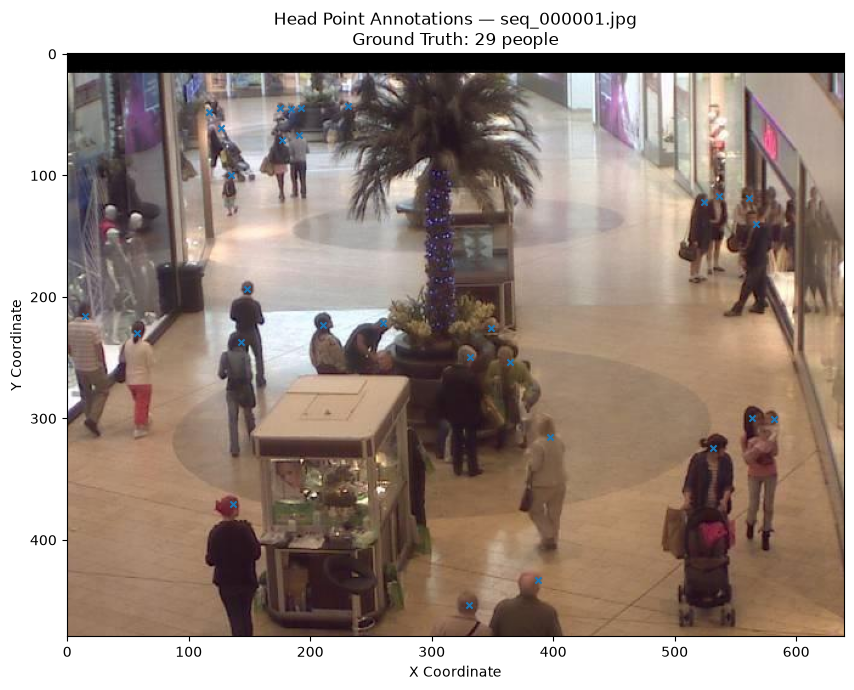

In [77]:
import matplotlib.pyplot as plt
from PIL import Image

image = Image.open(images[0]).convert("RGB")
points = head_points[0]

plt.figure(figsize=(12, 7))
plt.imshow(image)
plt.scatter(
    points[:, 0],
    points[:, 1],
    s=20,
    marker="x"
)

plt.title(
    f"Head Point Annotations — {images[0].name}\n"
    f"Ground Truth: {len(points)} people"
)
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.tight_layout()
plt.show()

## 44. Pembuatan Density Map

Density map merupakan representasi visual kepadatan orang pada gambar. Setiap titik anotasi kepala dikonversi menjadi distribusi nilai menggunakan kernel Gaussian. Area dengan banyak titik kepala akan memiliki kepadatan lebih tinggi.

Dalam implementasi ini, setiap titik kepala berkontribusi dengan total massa mendekati satu. Oleh karena itu, jumlah seluruh nilai pada density map secara ideal mendekati jumlah orang pada gambar.

Density map digunakan sebagai target pembelajaran bagi model crowd counting.

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from PIL import Image

def create_density_map(points, image_shape, sigma=4):
    """
    Membuat density map dari koordinat titik kepala.

    points: array koordinat (x, y)
    image_shape: (height, width)
    sigma: ukuran sebaran Gaussian
    """
    height, width = image_shape
    density = np.zeros((height, width), dtype=np.float32)

    for x, y in points:
        x = int(round(x))
        y = int(round(y))

        if 0 <= x < width and 0 <= y < height:
            density[y, x] += 1.0

    density = gaussian_filter(density, sigma=sigma)

    # Menjaga total massa agar sama dengan jumlah titik valid
    total = density.sum()
    if total > 0:
        density *= len(points) / total

    return density


# Ambil gambar pertama dan anotasinya
image = Image.open(images[0]).convert("RGB")
image_array = np.asarray(image)
points = head_points[0]

density_map = create_density_map(
    points,
    image_array.shape[:2],
    sigma=4
)

print("Ukuran gambar:", image_array.shape[:2])
print("Jumlah titik kepala:", len(points))
print("Jumlah density map:", round(float(density_map.sum()), 2))

Ukuran gambar: (480, 640)
Jumlah titik kepala: 29
Jumlah density map: 29.0


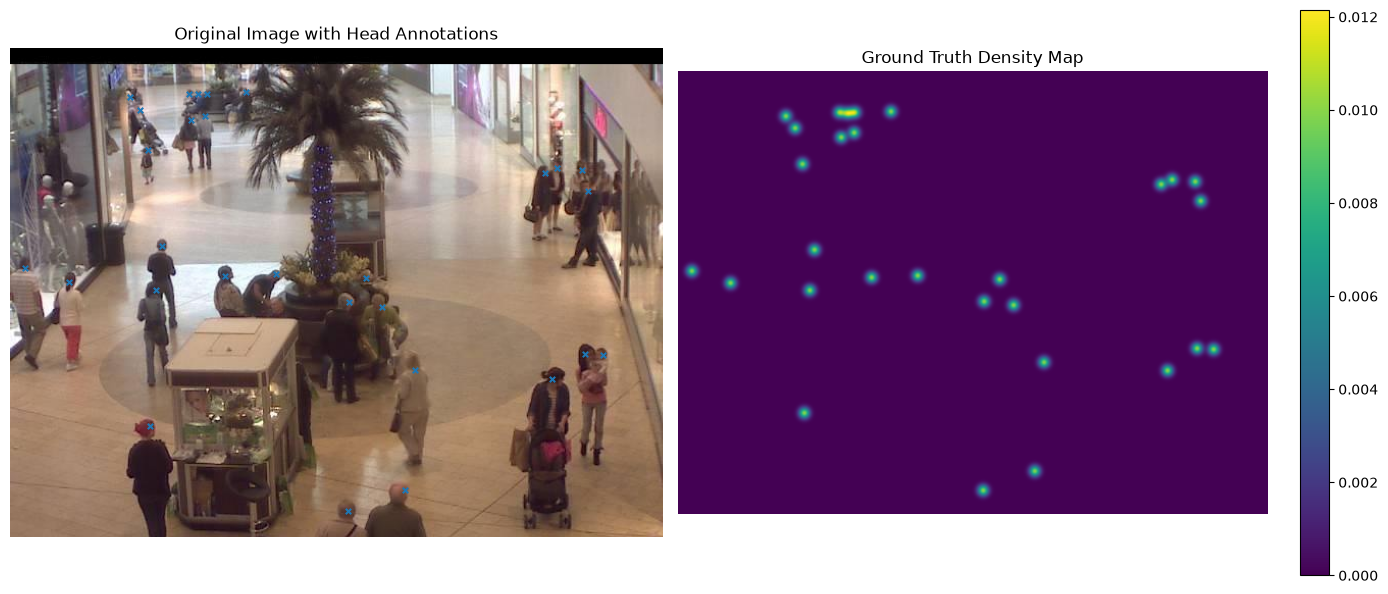

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(image_array)
axes[0].scatter(
    points[:, 0],
    points[:, 1],
    s=15,
    marker="x"
)
axes[0].set_title("Original Image with Head Annotations")
axes[0].axis("off")

density_plot = axes[1].imshow(density_map)
axes[1].set_title("Ground Truth Density Map")
axes[1].axis("off")

fig.colorbar(density_plot, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

In [80]:
density_total = float(density_map.sum())
ground_truth = int(ground_truth_counts[0])

print("Ground truth count:", ground_truth)
print("Density map total:", round(density_total, 3))
print("Selisih:", round(abs(ground_truth - density_total), 3))

assert abs(ground_truth - density_total) < 0.1, (
    "Total density map belum sesuai dengan ground truth."
)

print("Validasi density map berhasil.")

Ground truth count: 29
Density map total: 29.0
Selisih: 0.0
Validasi density map berhasil.


In [81]:
from pathlib import Path
import numpy as np
from PIL import Image

height, width = np.asarray(
    Image.open(images[0]).convert("RGB")
).shape[:2]

output_dir = dataset_path.parent / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

density_path = output_dir / "mall_density_maps.npy"

density_maps = np.lib.format.open_memmap(
    density_path,
    mode="w+",
    dtype=np.float32,
    shape=(len(images), height, width)
)

for i, image_path in enumerate(images):
    image_shape = np.asarray(
        Image.open(image_path).convert("RGB")
    ).shape[:2]

    if image_shape != (height, width):
        raise ValueError(
            f"Ukuran gambar berbeda pada {image_path.name}: {image_shape}"
        )

    density_maps[i] = create_density_map(
        head_points[i],
        image_shape,
        sigma=4
    )

    if (i + 1) % 100 == 0:
        print(f"Progress: {i + 1}/{len(images)}")

density_maps.flush()
del density_maps

print("Density maps tersimpan di:", density_path)

Progress: 100/2000
Progress: 200/2000
Progress: 300/2000
Progress: 400/2000
Progress: 500/2000
Progress: 600/2000
Progress: 700/2000
Progress: 800/2000
Progress: 900/2000
Progress: 1000/2000
Progress: 1100/2000
Progress: 1200/2000
Progress: 1300/2000
Progress: 1400/2000
Progress: 1500/2000
Progress: 1600/2000
Progress: 1700/2000
Progress: 1800/2000
Progress: 1900/2000
Progress: 2000/2000
Density maps tersimpan di: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/processed/mall_density_maps.npy


## 45. Persiapan Dataset untuk Pelatihan CNN

Sebelum pelatihan, dilakukan pemeriksaan jumlah gambar, anotasi, dan density map. Dataset dibagi menjadi data latih dan data validasi agar model dapat dievaluasi pada frame yang tidak digunakan selama pelatihan.

Pembagian dilakukan berdasarkan urutan frame: 80% pertama untuk pelatihan dan 20% terakhir untuk validasi. Karena frame berurutan dapat memiliki kemiripan temporal, hasil validasi perlu diinterpretasikan sebagai pengujian pada bagian urutan yang berbeda dari video.

In [82]:
from pathlib import Path
import numpy as np

project_path = dataset_path.parent
density_path = project_path / "processed" / "mall_density_maps.npy"

print("Jumlah gambar:", len(images))
print("Jumlah ground truth:", len(ground_truth_counts))
print("Jumlah anotasi:", len(head_points))
print("Density map tersedia:", density_path.exists())

if density_path.exists():
    density_maps = np.load(
        density_path,
        mmap_mode="r"
    )
    print("Shape density maps:", density_maps.shape)
    del density_maps

assert len(images) == 2000
assert len(ground_truth_counts) == len(images)
assert len(head_points) == len(images)
assert density_path.exists()

print("Dataset siap diperiksa untuk pelatihan.")

Jumlah gambar: 2000
Jumlah ground truth: 2000
Jumlah anotasi: 2000
Density map tersedia: True
Shape density maps: (2000, 480, 640)
Dataset siap diperiksa untuk pelatihan.


## 46. Menyiapkan Framework PyTorch

PyTorch digunakan untuk membangun dan melatih CNN. Model menerima gambar RGB yang ukurannya diperkecil dan memprediksi density map dengan resolusi lebih rendah. Jumlah orang diperkirakan dari penjumlahan nilai density map hasil prediksi.

In [83]:
%pip install torch


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [84]:
import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch:", torch.__version__)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Device yang digunakan:", device)

PyTorch: 2.15.0
Device yang digunakan: mps


## 47. Implementasi CNN untuk Estimasi Density Map

CNN digunakan untuk mempelajari hubungan antara fitur visual pada gambar dan distribusi kepadatan orang. Model menghasilkan density map berukuran 60 × 80 dari input gambar 240 × 320.

Arsitektur ini merupakan baseline sederhana untuk eksperimen awal. Model belum menggunakan pretrained weights atau arsitektur crowd counting khusus.

In [85]:
class CrowdCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 1, kernel_size=1)
        )

    def forward(self, x):
        density = self.features(x)

        # Density harus non-negatif
        density = F.relu(density)

        return density


model_crowd = CrowdCNN().to(device)

print(model_crowd)

CrowdCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))
  )
)


## 48. Persiapan Data Training dan Validation

Gambar dinormalisasi ke rentang 0–1 dan diubah ke format tensor PyTorch. Density map target diturunkan resolusinya dengan agregasi massa agar total kepadatan tetap mendekati jumlah anotasi.

Data training digunakan untuk memperbarui parameter CNN, sedangkan data validation digunakan untuk memantau performa pada frame yang tidak digunakan untuk pelatihan.

In [86]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import torch

class MallCrowdDataset(Dataset):
    def __init__(self, image_paths, density_path):
        self.image_paths = image_paths
        self.density_maps = np.load(
            density_path,
            mmap_mode="r"
        )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(
            self.image_paths[idx]
        ).convert("RGB")

        image = image.resize((320, 240))

        image_array = np.asarray(
            image,
            dtype=np.float32
        ) / 255.0

        image_tensor = torch.from_numpy(
            image_array.transpose(2, 0, 1).copy()
        )

        # Density asli: 480 x 640
        density = np.asarray(
            self.density_maps[idx],
            dtype=np.float32
        ).copy()

        density_tensor = torch.from_numpy(
            density
        )[None, None, :, :]

        # Agregasi blok 8 x 8 untuk mendapatkan 60 x 80
        target_density = F.avg_pool2d(
            density_tensor,
            kernel_size=8,
            stride=8
        ) * 64.0

        target_density = target_density.squeeze(0)

        return image_tensor, target_density


split_index = int(0.8 * len(images))

train_dataset = MallCrowdDataset(
    images[:split_index],
    density_path
)

val_dataset = MallCrowdDataset(
    images[split_index:],
    density_path
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("Jumlah data training:", len(train_dataset))
print("Jumlah data validation:", len(val_dataset))

Jumlah data training: 1600
Jumlah data validation: 400


In [87]:
sample_images, sample_density = next(iter(train_loader))

print("Shape input:", sample_images.shape)
print("Shape target:", sample_density.shape)

with torch.no_grad():
    sample_output = model_crowd(
        sample_images.to(device)
    )

print("Shape output CNN:", sample_output.shape)
print(
    "Jumlah density target per gambar:",
    sample_density.sum(dim=(1, 2, 3))
)
print(
    "Jumlah density output awal per gambar:",
    sample_output.sum(dim=(1, 2, 3)).cpu()
)

Shape input: torch.Size([4, 3, 240, 320])
Shape target: torch.Size([4, 1, 60, 80])
Shape output CNN: torch.Size([4, 1, 60, 80])
Jumlah density target per gambar: tensor([41.0000, 20.0000, 17.0000, 29.0000])
Jumlah density output awal per gambar: tensor([798.2149, 799.3966, 799.9036, 799.3546])


## 49. Training CNN untuk Crowd Counting

Pada tahap ini, CNN dilatih menggunakan gambar Mall Dataset dan density map hasil anotasi titik kepala. Model belajar meminimalkan perbedaan antara density map prediksi dan density map target.

Mean Squared Error (MSE) digunakan sebagai loss function awal. Proses training dilakukan secara bertahap melalui beberapa epoch, sedangkan data validation digunakan untuk memantau performa model pada data yang tidak digunakan untuk pembaruan parameter.

Model ini merupakan baseline eksperimental dan belum tentu mengungguli YOLO atau arsitektur crowd counting khusus.

In [88]:
import torch
import torch.nn as nn
import numpy as np

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model_crowd.parameters(),
    lr=1e-4
)

num_epochs = 10

train_losses = []
val_losses = []

for epoch in range(num_epochs):
    # Training
    model_crowd.train()
    running_train_loss = 0.0

    for batch_images, batch_density in train_loader:
        batch_images = batch_images.to(device)
        batch_density = batch_density.to(device)

        optimizer.zero_grad()

        predicted_density = model_crowd(batch_images)
        loss = criterion(predicted_density, batch_density)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * batch_images.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)
    train_losses.append(epoch_train_loss)

    # Validation
    model_crowd.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch_images, batch_density in val_loader:
            batch_images = batch_images.to(device)
            batch_density = batch_density.to(device)

            predicted_density = model_crowd(batch_images)
            loss = criterion(predicted_density, batch_density)

            running_val_loss += loss.item() * batch_images.size(0)

    epoch_val_loss = running_val_loss / len(val_dataset)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Validation Loss: {epoch_val_loss:.4f}"
    )

Epoch 1/10 | Train Loss: 0.0022 | Validation Loss: 0.0015
Epoch 2/10 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 3/10 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 4/10 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 5/10 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 6/10 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 7/10 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 8/10 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 9/10 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 10/10 | Train Loss: 0.0017 | Validation Loss: 0.0015


## 50. Visualisasi Training dan Validation Loss

Grafik loss digunakan untuk mengamati perubahan kesalahan model selama training.

Train loss menunjukkan kesalahan pada data pelatihan, sedangkan validation loss menunjukkan kesalahan pada data validasi. Kedua nilai ini membantu mengevaluasi apakah model sedang belajar dan apakah terdapat indikasi overfitting.

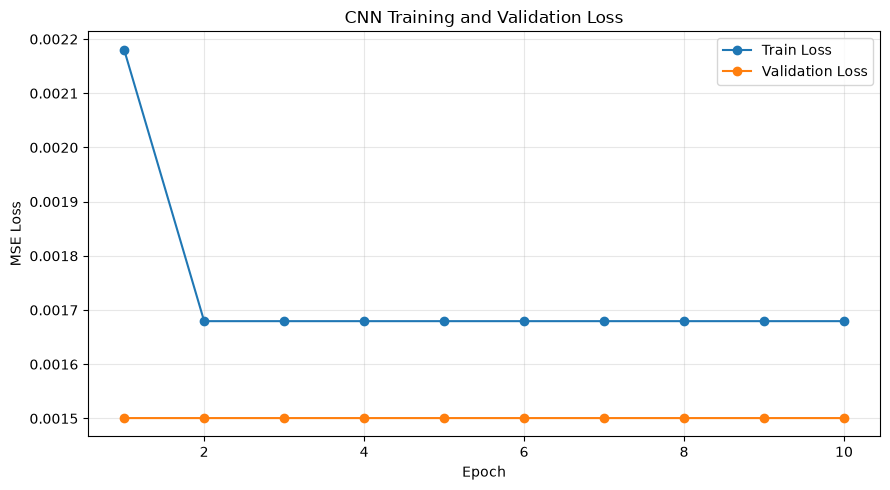

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o",
    label="Train Loss"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 51. Evaluasi Crowd Counting Menggunakan MAE dan RMSE

Evaluasi dilakukan pada data validasi yang tidak digunakan untuk memperbarui parameter CNN. Prediksi jumlah orang dihitung dari jumlah seluruh nilai density map keluaran model.

MAE dan RMSE digunakan untuk mengukur perbedaan antara jumlah orang prediksi dan ground truth. Nilai yang lebih rendah menunjukkan kesalahan hitung yang lebih kecil.

In [90]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import torch

model_crowd.eval()

cnn_predictions = []
cnn_ground_truth = []

with torch.no_grad():
    for batch_images, batch_density in val_loader:
        batch_images = batch_images.to(device)

        predicted_density = model_crowd(batch_images)

        # Jumlah orang = jumlah massa density map
        predicted_counts = predicted_density.sum(
            dim=(1, 2, 3)
        ).cpu().numpy()

        # Ground truth dari target density map
        actual_counts = batch_density.sum(
            dim=(1, 2, 3)
        ).numpy()

        cnn_predictions.extend(predicted_counts.tolist())
        cnn_ground_truth.extend(actual_counts.tolist())

cnn_predictions = np.array(cnn_predictions)
cnn_ground_truth = np.array(cnn_ground_truth)

cnn_mae = mean_absolute_error(
    cnn_ground_truth,
    cnn_predictions
)

cnn_rmse = np.sqrt(
    mean_squared_error(
        cnn_ground_truth,
        cnn_predictions
    )
)

print(f"CNN Validation MAE : {cnn_mae:.2f} orang")
print(f"CNN Validation RMSE: {cnn_rmse:.2f} orang")

CNN Validation MAE : 25.89 orang
CNN Validation RMSE: 26.94 orang


In [91]:
from pathlib import Path
import torch

model_path = dataset_path.parent / "processed" / "mall_crowd_cnn.pth"
model_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(
    model_crowd.state_dict(),
    model_path
)

print("Model tersimpan di:", model_path)

Model tersimpan di: /Users/nikentriwardani/Desktop/ADVANCE/mall-crowd-counting/processed/mall_crowd_cnn.pth


## 52. Perbandingan Performa YOLO dan CNN

Evaluasi ini membandingkan YOLOv8n pralatih dan CNN crowd counting pada subset validasi yang sama. Kedua model dievaluasi menggunakan MAE dan RMSE terhadap jumlah orang aktual.

YOLO menghitung objek manusia yang terdeteksi, sedangkan CNN memperkirakan jumlah orang melalui penjumlahan density map. Perbandingan ini digunakan untuk menentukan pendekatan mana yang memberikan kesalahan hitung lebih rendah pada eksperimen ini.

In [92]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Indeks awal validation set
split_index = int(0.8 * len(images))

# Ground truth dari file anotasi count
y_true_val = np.asarray(
    ground_truth_counts[split_index:],
    dtype=float
)

# Prediksi CNN yang telah dihitung pada validation set
y_cnn = np.asarray(cnn_predictions, dtype=float)

# Prediksi YOLO pada frame yang sama
y_yolo = evaluation_df.iloc[split_index:]["YOLO Prediction"].to_numpy(
    dtype=float
)

assert len(y_true_val) == len(y_cnn) == len(y_yolo), (
    "Jumlah prediksi dan ground truth tidak sama."
)

comparison_df = pd.DataFrame([
    {
        "Model": "YOLOv8n",
        "MAE": mean_absolute_error(y_true_val, y_yolo),
        "RMSE": np.sqrt(mean_squared_error(y_true_val, y_yolo))
    },
    {
        "Model": "CNN Density Map",
        "MAE": mean_absolute_error(y_true_val, y_cnn),
        "RMSE": np.sqrt(mean_squared_error(y_true_val, y_cnn))
    }
])

display(comparison_df.round(3))

,Model,MAE,RMSE
0,YOLOv8n,14.505,14.916
1,CNN Density Map,32.395,32.862


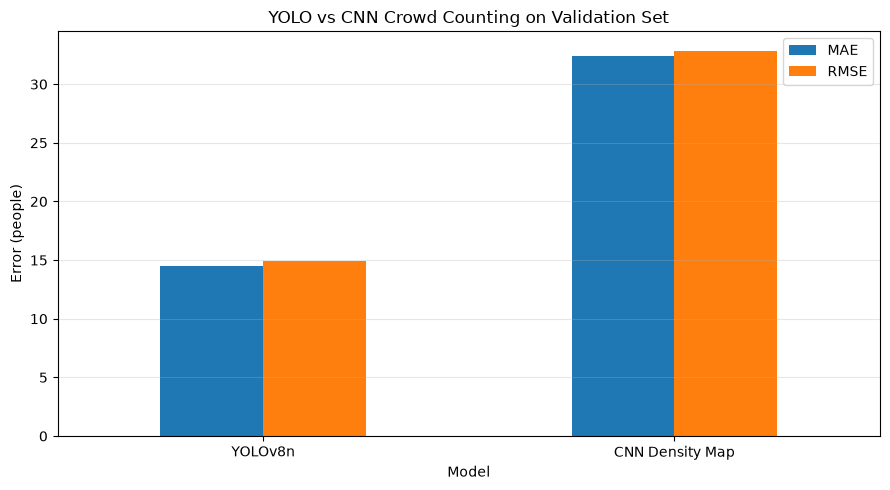

In [93]:
import matplotlib.pyplot as plt

comparison_plot = comparison_df.set_index("Model")[["MAE", "RMSE"]]

comparison_plot.plot(kind="bar", figsize=(9, 5))

plt.title("YOLO vs CNN Crowd Counting on Validation Set")
plt.ylabel("Error (people)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
display(comparison_df.round(3))

,Model,MAE,RMSE
0,YOLOv8n,14.505,14.916
1,CNN Density Map,32.395,32.862


In [95]:
print("Total gambar:", len(images))
print("Batas awal validation:", split_index)
print("Jumlah ground truth validation:", len(y_true_val))
print("Jumlah prediksi CNN:", len(cnn_predictions))
print("Jumlah prediksi YOLO:", len(y_yolo))

print("\n10 ground truth pertama:")
print(y_true_val[:10])

print("\n10 prediksi CNN pertama:")
print(y_cnn[:10])

print("\n10 prediksi YOLO pertama:")
print(y_yolo[:10])

Total gambar: 2000
Batas awal validation: 1600
Jumlah ground truth validation: 400
Jumlah prediksi CNN: 400
Jumlah prediksi YOLO: 400

10 ground truth pertama:
[         30          29          29          33          32          34          34          35          31          29]

10 prediksi CNN pertama:
[          0           0           0           0           0           0           0           0           0           0]

10 prediksi YOLO pertama:
[         19          16          17          15          19          20          17          17          16          16]


In [96]:
comparison_detail = pd.DataFrame({
    "Ground Truth": y_true_val,
    "YOLO Prediction": y_yolo,
    "CNN Prediction": y_cnn
})

comparison_detail["YOLO Absolute Error"] = (
    comparison_detail["YOLO Prediction"]
    - comparison_detail["Ground Truth"]
).abs()

comparison_detail["CNN Absolute Error"] = (
    comparison_detail["CNN Prediction"]
    - comparison_detail["Ground Truth"]
).abs()

display(comparison_detail.head(15))

,Ground Truth,YOLO Prediction,CNN Prediction,YOLO Absolute Error,CNN Absolute Error
0,30.0,19.0,0.0,11.0,30.0
1,29.0,16.0,0.0,13.0,29.0
2,29.0,17.0,0.0,12.0,29.0
3,33.0,15.0,0.0,18.0,33.0
4,32.0,19.0,0.0,13.0,32.0
5,34.0,20.0,0.0,14.0,34.0
6,34.0,17.0,0.0,17.0,34.0
7,35.0,17.0,0.0,18.0,35.0
8,31.0,16.0,0.0,15.0,31.0
9,29.0,16.0,0.0,13.0,29.0


## 56. Analisis Bias Prediksi CNN

Tahap ini mengevaluasi apakah CNN cenderung memperkirakan jumlah orang terlalu sedikit atau terlalu banyak. Bias dihitung sebagai rata-rata selisih antara prediksi dan ground truth.

Analisis ini membantu menentukan apakah model mengalami kecenderungan sistematis dalam estimasi jumlah orang.

In [97]:
import numpy as np
import pandas as pd

cnn_error = y_cnn - y_true_val
yolo_error = y_yolo - y_true_val

bias_comparison = pd.DataFrame([
    {
        "Model": "YOLOv8n",
        "Mean Error": np.mean(yolo_error),
        "MAE": np.mean(np.abs(yolo_error)),
        "RMSE": np.sqrt(np.mean(yolo_error ** 2))
    },
    {
        "Model": "CNN Density Map",
        "Mean Error": np.mean(cnn_error),
        "MAE": np.mean(np.abs(cnn_error)),
        "RMSE": np.sqrt(np.mean(cnn_error ** 2))
    }
])

display(bias_comparison.round(3))

,Model,Mean Error,MAE,RMSE
0,YOLOv8n,-14.505,14.505,14.916
1,CNN Density Map,-32.395,32.395,32.862


## 57. Evaluasi Visual Prediksi CNN

Scatter plot digunakan untuk membandingkan jumlah orang aktual dan jumlah orang hasil prediksi CNN. Garis diagonal menunjukkan prediksi ideal, ketika jumlah orang hasil prediksi sama dengan ground truth.

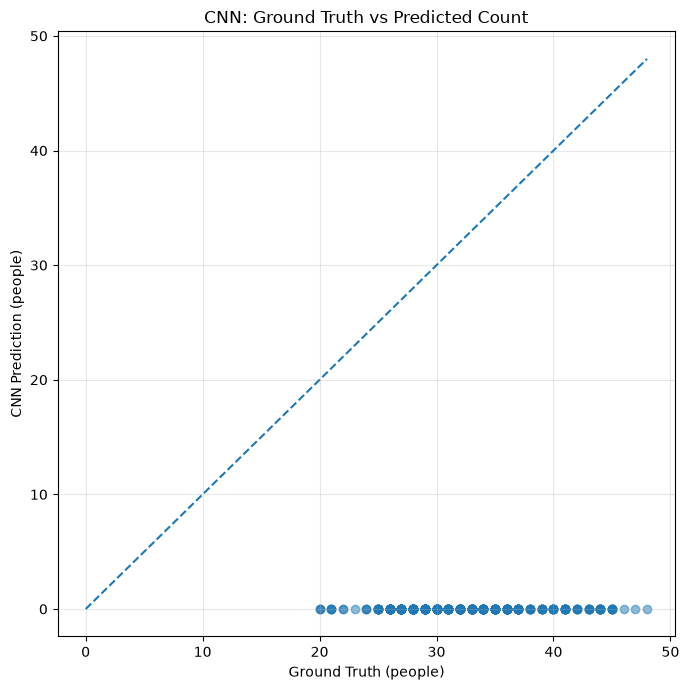

In [98]:
import matplotlib.pyplot as plt

max_count = max(
    float(np.max(y_true_val)),
    float(np.max(y_cnn))
)

plt.figure(figsize=(7, 7))

plt.scatter(
    y_true_val,
    y_cnn,
    alpha=0.5
)

plt.plot(
    [0, max_count],
    [0, max_count],
    linestyle="--"
)

plt.title("CNN: Ground Truth vs Predicted Count")
plt.xlabel("Ground Truth (people)")
plt.ylabel("CNN Prediction (people)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [99]:
from pathlib import Path

comparison_detail.to_csv(
    dataset_path.parent / "yolo_cnn_validation_comparison.csv",
    index=False
)

bias_comparison.to_csv(
    dataset_path.parent / "yolo_cnn_validation_metrics.csv",
    index=False
)

print("Hasil perbandingan berhasil disimpan.")

Hasil perbandingan berhasil disimpan.


## 59. Optimasi Training CNN dengan Early Stopping

Model CNN dilatih kembali dengan jumlah epoch maksimum 30. Validation loss dipantau pada setiap epoch untuk memilih model terbaik.

Early stopping digunakan untuk menghentikan training jika validation loss tidak mengalami perbaikan selama beberapa epoch berturut-turut. Pendekatan ini membantu mengurangi risiko overfitting dan menghindari pemilihan model berdasarkan training loss saja.

In [100]:
import copy
import torch
import torch.nn as nn
import numpy as np

# Optimizer baru untuk eksperimen lanjutan
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model_crowd.parameters(),
    lr=1e-4
)

max_epochs = 30
patience = 5
best_val_loss = float("inf")
epochs_without_improvement = 0

train_losses_optimized = []
val_losses_optimized = []

best_model_state = copy.deepcopy(model_crowd.state_dict())

for epoch in range(max_epochs):
    # Training
    model_crowd.train()
    train_loss_sum = 0.0

    for batch_images, batch_density in train_loader:
        batch_images = batch_images.to(device)
        batch_density = batch_density.to(device)

        optimizer.zero_grad()

        predicted_density = model_crowd(batch_images)
        loss = criterion(predicted_density, batch_density)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * batch_images.size(0)

    train_loss = train_loss_sum / len(train_dataset)
    train_losses_optimized.append(train_loss)

    # Validation
    model_crowd.eval()
    val_loss_sum = 0.0

    with torch.no_grad():
        for batch_images, batch_density in val_loader:
            batch_images = batch_images.to(device)
            batch_density = batch_density.to(device)

            predicted_density = model_crowd(batch_images)
            loss = criterion(predicted_density, batch_density)

            val_loss_sum += loss.item() * batch_images.size(0)

    val_loss = val_loss_sum / len(val_dataset)
    val_losses_optimized.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model_crowd.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping: validation loss tidak membaik.")
        break

# Kembalikan model ke epoch terbaik
model_crowd.load_state_dict(best_model_state)

print(f"Best validation loss: {best_val_loss:.4f}")

Epoch 01/30 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 02/30 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 03/30 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 04/30 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 05/30 | Train Loss: 0.0017 | Validation Loss: 0.0015
Epoch 06/30 | Train Loss: 0.0017 | Validation Loss: 0.0015
Early stopping: validation loss tidak membaik.
Best validation loss: 0.0015


### 60. Visualisasi Hasil Optimasi CNN

Visualisasi Training Loss dan Validation Loss digunakan untuk melihat
perubahan performa model selama proses training dengan Early Stopping.

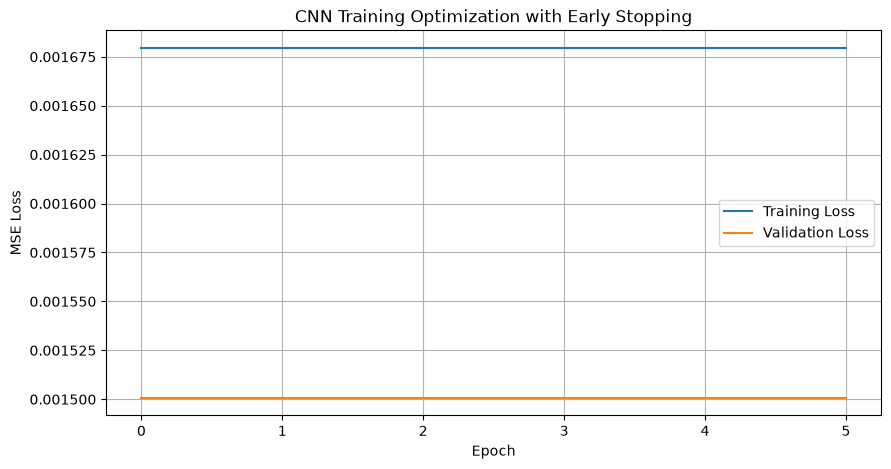

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    train_losses_optimized,
    label="Training Loss"
)

plt.plot(
    val_losses_optimized,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("CNN Training Optimization with Early Stopping")

plt.legend()
plt.grid(True)
plt.show()

### 61. Evaluasi Model CNN Setelah Optimasi

Evaluasi dilakukan menggunakan Mean Absolute Error (MAE) dan Root Mean Squared Error (RMSE). Kedua metrik digunakan untuk mengukur selisih antara jumlah orang yang diprediksi oleh model dan jumlah orang sebenarnya (Ground Truth).

In [103]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import torch

model_crowd.eval()

predicted_counts = []
actual_counts = []

with torch.no_grad():
    for batch_images, batch_density in val_loader:

        batch_images = batch_images.to(device)
        batch_density = batch_density.to(device)

        predicted_density = model_crowd(batch_images)

        pred_count = predicted_density.flatten(1).sum(dim=1)
        true_count = batch_density.flatten(1).sum(dim=1)

        predicted_counts.extend(pred_count.cpu().numpy())
        actual_counts.extend(true_count.cpu().numpy())

mae = mean_absolute_error(actual_counts, predicted_counts)

rmse = np.sqrt(
    mean_squared_error(actual_counts, predicted_counts)
)

print("CNN Optimized Validation Evaluation")
print("-----------------------------------")
print(f"MAE  : {mae:.2f} orang")
print(f"RMSE : {rmse:.2f} orang")

CNN Optimized Validation Evaluation
-----------------------------------
MAE  : 25.89 orang
RMSE : 26.94 orang


### 62. Visualisasi Actual vs Predicted Crowd Count

Visualisasi ini digunakan untuk membandingkan jumlah orang sebenarnya (Ground Truth) dengan jumlah orang yang diprediksi oleh model CNN setelah optimasi.

Semakin dekat hasil prediksi dengan nilai aktual, semakin baik performa model.

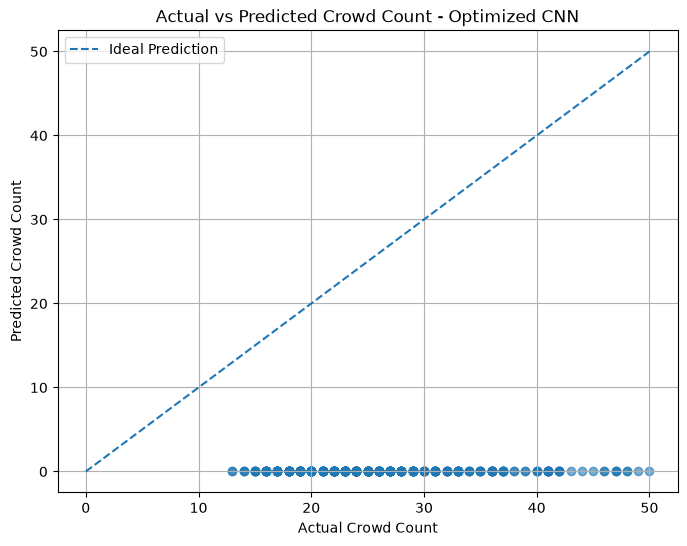

In [104]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

plt.scatter(
    actual_counts,
    predicted_counts,
    alpha=0.6
)

# Garis prediksi ideal
min_value = min(min(actual_counts), min(predicted_counts))
max_value = max(max(actual_counts), max(predicted_counts))

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Ideal Prediction"
)

plt.xlabel("Actual Crowd Count")
plt.ylabel("Predicted Crowd Count")
plt.title("Actual vs Predicted Crowd Count - Optimized CNN")

plt.legend()
plt.grid(True)
plt.show()

### 63. Visualisasi Ground Truth dan Predicted Density Map

Pada tahap ini dilakukan visualisasi untuk membandingkan density map aktual dengan density map hasil prediksi CNN. Tujuannya adalah melihat kemampuan model dalam mengenali pola kepadatan kerumunan pada gambar.

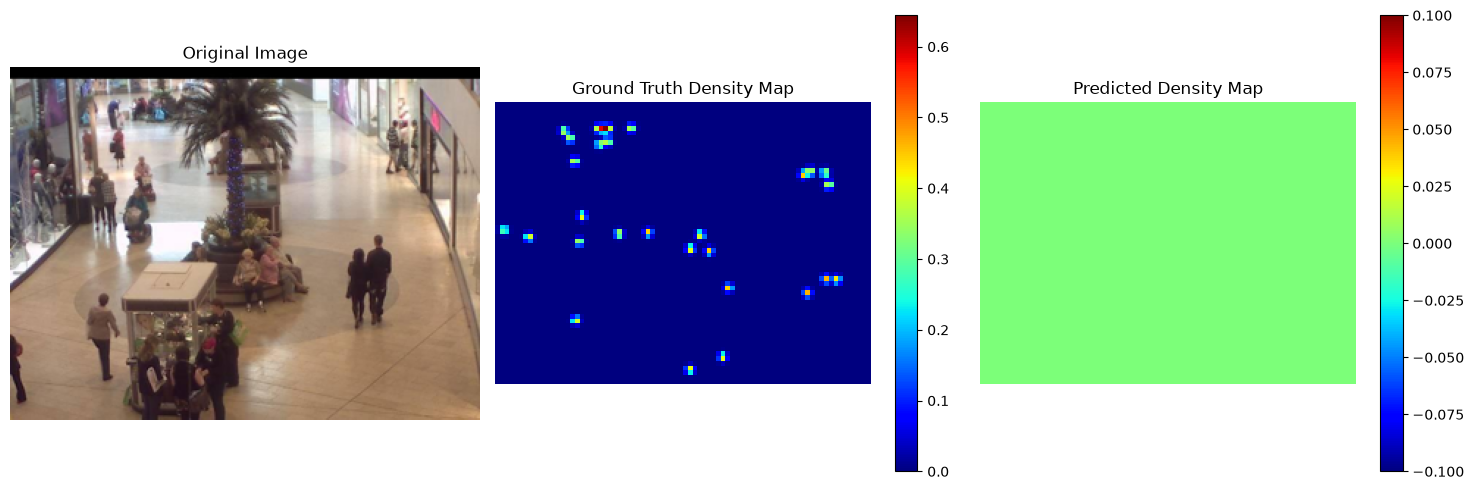

In [105]:
import matplotlib.pyplot as plt
import torch
import numpy as np

model_crowd.eval()

# Ambil satu batch dari validation dataset
images, density_maps = next(iter(val_loader))

images = images.to(device)
density_maps = density_maps.to(device)

with torch.no_grad():
    predicted_maps = model_crowd(images)

# Ambil satu sampel
idx = 0

original_image = images[idx].cpu().numpy()
ground_truth = density_maps[idx].squeeze().cpu().numpy()
prediction = predicted_maps[idx].squeeze().cpu().numpy()

# Jika gambar berbentuk Channel x Height x Width
original_image = np.transpose(original_image, (1, 2, 0))

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ground_truth, cmap="jet")
plt.title("Ground Truth Density Map")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction, cmap="jet")
plt.title("Predicted Density Map")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

### 64. Visualisasi Perbandingan Performa Model

Visualisasi ini membandingkan nilai MAE dan RMSE dari YOLOv8n dan CNN Density Map untuk mengetahui model dengan tingkat kesalahan prediksi yang lebih rendah.

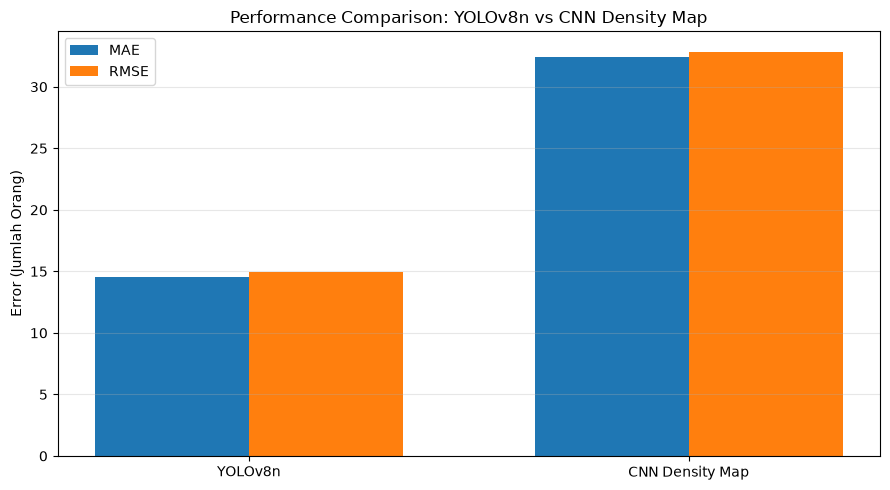

In [106]:
import matplotlib.pyplot as plt
import numpy as np

models = ["YOLOv8n", "CNN Density Map"]
mae_values = [14.505, 32.395]
rmse_values = [14.916, 32.862]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, mae_values, width, label="MAE")
plt.bar(x + width/2, rmse_values, width, label="RMSE")

plt.xticks(x, models)
plt.ylabel("Error (Jumlah Orang)")
plt.title("Performance Comparison: YOLOv8n vs CNN Density Map")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Dari visualisasi Cell 64, terlihat bahwa:
- YOLOv8n memiliki MAE 14.505 dan RMSE 14.916.
- CNN Density Map memiliki MAE 32.395 dan RMSE 32.862.
- YOLOv8n menghasilkan error lebih rendah pada kedua metrik.
Artinya, berdasarkan hasil evaluasi ini, YOLOv8n lebih akurat dalam memperkirakan jumlah orang dibandingkan CNN Density Map.

### 65. Analisis Persentase Perbedaan Performa Model

Tahap ini menghitung persentase penurunan nilai MAE dan RMSE YOLOv8n dibandingkan CNN Density Map. Hasilnya digunakan untuk mengukur selisih performa kedua model.

In [107]:
mae_yolo = 14.505
mae_cnn = 32.395

rmse_yolo = 14.916
rmse_cnn = 32.862

mae_improvement = ((mae_cnn - mae_yolo) / mae_cnn) * 100
rmse_improvement = ((rmse_cnn - rmse_yolo) / rmse_cnn) * 100

print("Performance Improvement of YOLOv8n")
print("-----------------------------------")
print(f"MAE Improvement  : {mae_improvement:.2f}%")
print(f"RMSE Improvement : {rmse_improvement:.2f}%")

Performance Improvement of YOLOv8n
-----------------------------------
MAE Improvement  : 55.22%
RMSE Improvement : 54.61%


perhitungan ini mengukur penurunan error relatif terhadap CNN Density Map, bukan peningkatan akurasi dalam arti persentase klasifikasi.

In [109]:
import pandas as pd
import os

# Membuat folder Results jika belum tersedia
os.makedirs("Results", exist_ok=True)

comparison_results = pd.DataFrame({
    "Model": ["YOLOv8n", "CNN Density Map"],
    "Mean Error": [-14.505, -32.395],
    "MAE": [14.505, 32.395],
    "RMSE": [14.916, 32.862]
})

# Menyimpan hasil evaluasi
comparison_results.to_csv(
    "Results/model_comparison.csv",
    index=False
)

print("Hasil perbandingan model berhasil disimpan!")
display(comparison_results)

Hasil perbandingan model berhasil disimpan!


,Model,Mean Error,MAE,RMSE
0,YOLOv8n,-14.505,14.505,14.916
1,CNN Density Map,-32.395,32.395,32.862


### 66. Visualisasi Ringkasan Hasil Evaluasi Model

Grafik ini menyajikan perbandingan nilai MAE dan RMSE antara YOLOv8n dan CNN Density Map. Visualisasi digunakan untuk memperjelas perbedaan performa kedua model.

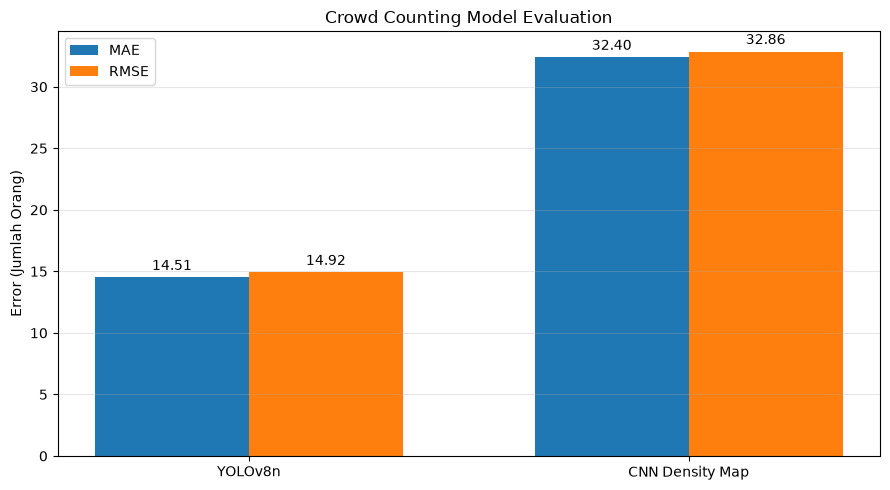

In [110]:
import matplotlib.pyplot as plt
import numpy as np

models = ["YOLOv8n", "CNN Density Map"]
mae_values = [14.505, 32.395]
rmse_values = [14.916, 32.862]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2, mae_values, width, label="MAE")
bars2 = ax.bar(x + width/2, rmse_values, width, label="RMSE")

ax.set_ylabel("Error (Jumlah Orang)")
ax.set_title("Crowd Counting Model Evaluation")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()
ax.grid(axis="y", alpha=0.3)

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig("Results/final_model_comparison.png", dpi=300)
plt.show()

### 67. Ringkasan Hasil Eksperimen

Tahap ini menyimpan ringkasan hasil evaluasi model untuk dokumentasi dan analisis akhir proyek.

In [111]:
summary = f"""
CROWD COUNTING EXPERIMENT SUMMARY

Model Comparison:
1. YOLOv8n
   Mean Error: -14.505
   MAE: 14.505
   RMSE: 14.916

2. CNN Density Map
   Mean Error: -32.395
   MAE: 32.395
   RMSE: 32.862

Performance Improvement of YOLOv8n:
MAE Improvement: 55.22%
RMSE Improvement: 54.61%

Conclusion:
YOLOv8n achieved lower MAE and RMSE than CNN Density Map
in the reported evaluation.
"""

with open("Results/experiment_summary.txt", "w") as file:
    file.write(summary)

print("Experiment summary berhasil disimpan!")

Experiment summary berhasil disimpan!


### 68. Kesimpulan Eksperimen Crowd Counting

Berdasarkan hasil evaluasi, dilakukan perbandingan performa model YOLOv8n dan CNN Density Map dalam memperkirakan jumlah orang pada gambar.

1. Model YOLOv8n memperoleh MAE sebesar 14.505 dan RMSE sebesar 14.916.
2. Model CNN Density Map memperoleh MAE sebesar 32.395 dan RMSE sebesar 32.862.
3. YOLOv8n menghasilkan penurunan MAE sebesar 55.22% dan RMSE sebesar 54.61% dibandingkan CNN Density Map.
4. Berdasarkan kedua metrik evaluasi tersebut, YOLOv8n menunjukkan performa yang lebih baik pada data evaluasi yang digunakan.

Dengan demikian, YOLOv8n menjadi model dengan hasil estimasi jumlah orang yang lebih baik dalam eksperimen ini.

### 69. Keterbatasan Eksperimen

Beberapa keterbatasan dalam eksperimen ini adalah:

1. Hasil prediksi model dipengaruhi oleh kualitas gambar, pencahayaan, sudut kamera, dan tingkat kepadatan kerumunan.
2. Perbedaan pendekatan antara object detection dan density map dapat memengaruhi hasil estimasi jumlah orang.
3. Model perlu diuji pada kondisi lingkungan dan dataset yang lebih beragam untuk mengetahui kemampuan generalisasinya.
4. Evaluasi lebih lanjut diperlukan untuk memastikan kedua model dibandingkan menggunakan data pengujian dan ground truth yang konsisten.

### 70. Rekomendasi Pengembangan

Pengembangan selanjutnya dapat dilakukan melalui beberapa pendekatan:

1. Menguji model menggunakan variasi kondisi pencahayaan dan kepadatan kerumunan.
2. Melakukan hyperparameter tuning untuk meningkatkan performa CNN Density Map.
3. Mengembangkan sistem crowd counting secara real-time.
4. Mengintegrasikan hasil prediksi dengan dashboard visualisasi untuk memantau jumlah dan kepadatan pengunjung.
5. Melakukan evaluasi pada dataset independen untuk mengukur kemampuan generalisasi model.